<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-06/latent-space.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Latent space of a VAE

*Deep Learning for Scientific Discovery, Jagiellonian University. Author: Marcin Płodzień.*

A variational autoencoder (VAE) compresses every data point $\mathbf x$ into a vector $\mathbf z$ of a few latent numbers $z_1,\dots,z_d$ and learns to turn latent numbers back into data. On handwritten digits the latent plane of the lecture is a map on which digits of one class gather, but nobody knows what the two coordinates should mean, so it is hard to say whether the map is good, or what a point of it stands for. The difficulty disappears for data whose hidden generating numbers are chosen in advance: points on a curve, produced by one number, and images of a bar, produced by an angle and a shift. Because the true causes are known, every statement about the latent space can be checked against them: which latent value stands for which cause, how the decoder stretches the Gaussian prior into the data, what an encoder cloud means and when it grows, and in what sense the VAE is a probability model of the data.

The notation is that of the lecture: encoder $q_\phi(\mathbf z\,|\,\mathbf x)$, decoder $p_\theta(\mathbf x\,|\,\mathbf z)$ with mean $G(\mathbf z)$, prior $p(\mathbf z)$, $d$ latent coordinates.

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""                          # CPU only
import json, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Ellipse
import torch, torch.nn as nn, torch.nn.functional as F
from scipy.stats import norm
torch.set_num_threads(8)
import os
OUT = "figures"; os.makedirs(OUT, exist_ok=True); os.makedirs(OUT, exist_ok=True)       # figures of the slides
RES = "results"; os.makedirs(RES, exist_ok=True)                 # weights and numbers
blue, orange, navy, grey = "#005CA7", "#EB6709", "#0A2F5C", "#9A9A9A"
plt.rcParams.update({"font.size": 15, "axes.titlesize": 16, "axes.labelsize": 15, "xtick.labelsize": 13, "ytick.labelsize": 13,
                     "legend.fontsize": 13, "figure.titlesize": 17, "savefig.facecolor": "white", "figure.facecolor": "white"})
nums = {}                                                         # numbers quoted on the slides
def clean(ax):
    """Remove the top and right frame lines of an axes."""
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
def seed(k):
    """Fix the random generators of PyTorch and NumPy; return a NumPy generator."""
    torch.manual_seed(k); np.random.seed(k); return np.random.default_rng(k)
T0 = time.time()

## Hidden causes of data

Many data sets are far simpler than the space they live in. A photograph of a bar on a 28×28 sensor is a vector of 784 grey values, yet if the bar always has the same length and width, the whole picture is fixed by two numbers, its angle and its position. Images of one molecule in different conformations are fixed by a handful of torsion angles; the light curve of an eclipsing binary by a few orbital parameters; a galaxy image, to a good approximation, by its type, inclination, size and brightness. As the hidden numbers vary, the data points trace out a low-dimensional surface, a manifold, inside the high-dimensional data space. A curve drawn in a plane is the simplest case: one number, the position along the curve, fixes a point with two coordinates.

A latent-variable model turns this picture into a probability model. It assumes that a hidden vector $\mathbf z$ is drawn first and that the observation $\mathbf x$ is then produced from it with some noise. The distribution of the data is the average of the noise distributions over all hidden values,
$$p_\theta(\mathbf x)=\int p_\theta(\mathbf x\,|\,\mathbf z)\,p(\mathbf z)\,d\mathbf z . \tag{1}$$
Here $p(\mathbf z)$ is the prior, the distribution of the hidden vector before anything is observed, and $p_\theta(\mathbf x\,|\,\mathbf z)$ is the decoder, the distribution of observations produced by one hidden value, with network weights $\theta$. The VAE fixes the prior to the standard Gaussian in $d$ dimensions,
$$p(\mathbf z)=\mathcal N(0,I), \tag{2}$$
and learns the other direction as well: an encoder that, for an observed $\mathbf x$, returns a Gaussian cloud of the latent values that could have produced it,
$$q_\phi(\mathbf z\,|\,\mathbf x)=\mathcal N\big(\boldsymbol\mu_\phi(\mathbf x),\operatorname{diag}\boldsymbol\sigma_\phi^2(\mathbf x)\big). \tag{3}$$
The encoder network, with weights $\phi$, outputs the centre $\boldsymbol\mu$ and the widths $\boldsymbol\sigma$ (one per latent coordinate) of this cloud; $\operatorname{diag}\boldsymbol\sigma^2$ is the diagonal covariance matrix with the squared widths on its diagonal.

Nothing in equations (1)–(3) says that the coordinates of $\mathbf z$ must coincide with the true causes. The VAE is free to use any smooth relabelling of them, a stretched angle, a mirrored position, a mixture of the two. When the true causes are known, the relabelling chosen by the VAE can be compared with them directly.

## A curve in the plane

The first data set has one hidden number $t$, drawn uniformly from the interval $[-2,2]$. Each data point is a point of the sine curve with a horizontal coordinate $t$, blurred by a small Gaussian noise,
$$\mathbf x=\big(t,\ \sin 2t\big)+\boldsymbol\varepsilon,\qquad t\sim\mathcal U(-2,2),\qquad \boldsymbol\varepsilon\sim\mathcal N\big(0,s^2 I\big), \tag{4}$$
with noise level $s$ equal to 0.05. One sample is thus a pair of real numbers $(x_1,x_2)$, a point of the plane; $\mathcal U(-2,2)$ denotes the uniform distribution on the interval. The data set has $N$ = 4000 points; the hidden $t$ of each is kept for evaluation and never shown to the VAE.

first five samples   x1       x2      (hidden t)
                  0.475    0.893    ( 0.548)
                 -0.957   -1.023    (-0.921)
                 -1.900    0.480    (-1.836)
                 -1.958    0.672    (-1.934)
                  1.191    0.567    ( 1.253)


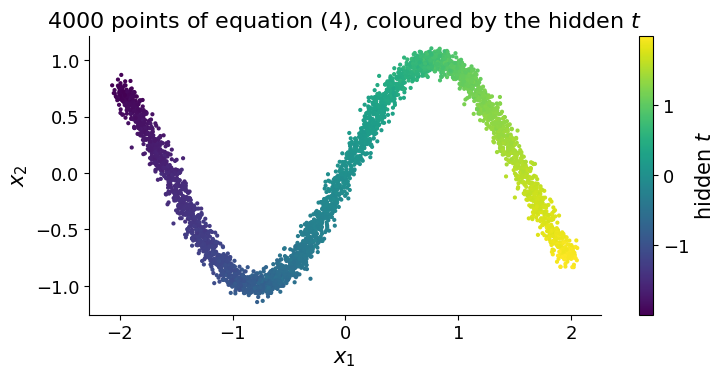

In [2]:
rng = seed(0)
N_c, s_noise = 4000, 0.05
t_c = rng.uniform(-2, 2, N_c)                                     # hidden cause of each point
X_c = np.stack([t_c, np.sin(2 * t_c)], 1) + s_noise * rng.standard_normal((N_c, 2))   # equation (4)
Xc_t = torch.tensor(X_c, dtype=torch.float32)
print("first five samples   x1       x2      (hidden t)")
for i in range(5): print(f"               {X_c[i,0]:8.3f} {X_c[i,1]:8.3f}    ({t_c[i]:6.3f})")

fig, ax = plt.subplots(figsize=(9, 4))
sc = ax.scatter(X_c[:, 0], X_c[:, 1], c=t_c, cmap="viridis", s=4)
plt.colorbar(sc, ax=ax, label="hidden $t$")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_title("4000 points of equation (4), coloured by the hidden $t$")
ax.set_aspect("equal"); clean(ax); plt.tight_layout(); plt.show()

The data fill a thin band around the curve; the colour, which the model never sees, changes steadily along it. A VAE with a single latent coordinate, $d$ = 1, has exactly the right number of hidden numbers.

The decoder must say how a point is spread around the curve for a given $z$. Since the noise in equation (4) is Gaussian, we take a Gaussian decoder whose mean $G(z)$ is a point of the plane computed by a network,
$$p_\theta(\mathbf x\,|\,z)=\mathcal N\big(\mathbf x;\,G(z),\,\sigma_x^2 I\big), \tag{5}$$
and fix its width $\sigma_x$ to the true noise level, 0.05. Minus the logarithm of equation (5) is a scaled squared error,
$$-\log p_\theta(\mathbf x\,|\,z)=\frac{\lVert\mathbf x-G(z)\rVert^2}{2\sigma_x^2}+\log\big(2\pi\sigma_x^2\big), \tag{6}$$
where the last term is a constant (for two coordinates). The width sets how strongly reconstruction errors are penalised compared with the KL term of equation (8). Fixing it to the known noise level makes equation (6) the exact negative log-likelihood of the data-generating process; a width learnt together with the networks would give the same model in principle, but it adds a parameter whose optimum drifts to the residual scatter of an imperfect decoder and couples it to the training dynamics. With the noise known, there is nothing to gain from learning it.

The second ingredient of the loss is the Kullback–Leibler (KL) divergence of the encoder cloud from the prior. For two distributions $q$ and $p$ of $z$ it is the average, under $q$, of the logarithm of their ratio,
$$\mathrm{KL}(q\,\|\,p)=\int q(z)\,\log\frac{q(z)}{p(z)}\,dz . \tag{7}$$
It is zero only when the two distributions coincide and positive otherwise; it measures, in nats, the extra surprise of describing samples of $q$ with the distribution $p$. For a Gaussian cloud, equation (3), and the prior of equation (2) it is a sum over latent coordinates,
$$\mathrm{KL}\big(q_\phi(\mathbf z\,|\,\mathbf x)\,\|\,p(\mathbf z)\big)=\frac12\sum_{k=1}^{d}\big(\mu_k^2+\sigma_k^2-\ln\sigma_k^2-1\big), \tag{8}$$
each term vanishing only for a cloud of centre 0 and width 1, a cloud that says nothing about $\mathbf x$. The latent value used in training is drawn from the cloud with the reparametrisation of the lecture,
$$\mathbf z=\boldsymbol\mu+\boldsymbol\sigma\odot\boldsymbol\eta,\qquad \boldsymbol\eta\sim\mathcal N(0,I), \tag{9}$$
where $\odot$ is the element-wise product and the random input $\boldsymbol\eta$ carries no weights, so that gradients flow through $\boldsymbol\mu$ and $\boldsymbol\sigma$. The loss of one data point is
$$\mathcal L_\beta(\mathbf x)=-\log p_\theta(\mathbf x\,|\,\mathbf z)+\beta\,\mathrm{KL}\big(q_\phi(\mathbf z\,|\,\mathbf x)\,\|\,p(\mathbf z)\big). \tag{10}$$
With $\beta$ = 1 its average over the data is minus the evidence lower bound (ELBO), a lower bound on the log-likelihood $\log p_\theta(\mathbf x)$ of equation (1), the "evidence" for the model:
$$\log p_\theta(\mathbf x)\ \ge\ \mathrm{ELBO}(\mathbf x)=\mathbb E_{q_\phi(\mathbf z|\mathbf x)}\big[\log p_\theta(\mathbf x\,|\,\mathbf z)\big]-\mathrm{KL}\big(q_\phi(\mathbf z\,|\,\mathbf x)\,\|\,p(\mathbf z)\big). \tag{11}$$
Other values of $\beta$ reweight the two terms.

In [3]:
class CurveVAE(nn.Module):
    """Dense VAE for points of the plane: encoder 2 -> 64 -> 64 -> (mu, ln sigma^2), decoder d -> 64 -> 64 -> 2."""
    def __init__(self, d=1, h=64):
        super().__init__()
        self.d = d
        self.enc = nn.Sequential(nn.Linear(2, h), nn.Tanh(), nn.Linear(h, h), nn.Tanh(), nn.Linear(h, 2 * d))
        self.dec = nn.Sequential(nn.Linear(d, h), nn.Tanh(), nn.Linear(h, h), nn.Tanh(), nn.Linear(h, 2))
    def encode(self, x):
        mu, logvar = self.enc(x).chunk(2, dim=1)                   # centre and log-width of the cloud, equation (3)
        return mu, logvar
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)   # equation (9)
        return self.dec(z), mu, logvar

def kl_gauss(mu, logvar):
    """KL divergence of N(mu, diag sigma^2) from N(0, I) for every row, equation (8)."""
    return 0.5 * (mu ** 2 + logvar.exp() - logvar - 1).sum(1)

def gauss_nll(x, xhat, sx):
    """Minus the log of the Gaussian decoder, equation (6), for every row (two coordinates)."""
    return ((x - xhat) ** 2).sum(1) / (2 * sx ** 2) + np.log(2 * np.pi * sx ** 2)

def train_vae(model, X, nll, beta=1.0, epochs=300, batch=128, lr=2e-3, report=50):
    """
    Minimise the mean of equation (10) over the data with Adam.

    model  : VAE whose forward(x) returns (decoder output, mu, ln sigma^2)
    X      : training data, a float tensor with one sample per row
    nll    : function (x, decoder output) -> minus the log of the decoder density per row
    beta   : weight of the KL term in equation (10)
    epochs : number of passes through the data
    batch  : mini-batch size
    lr     : learning rate of Adam
    report : print the two loss terms every `report` epochs
    """
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = []
    for ep in range(epochs):
        perm = torch.randperm(len(X)); r_sum = k_sum = 0.0
        for i in range(0, len(X), batch):
            xb = X[perm[i:i + batch]]
            out, mu, logvar = model(xb)
            rec, kl = nll(xb, out), kl_gauss(mu, logvar)
            loss = (rec + beta * kl).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            r_sum += rec.sum().item(); k_sum += kl.sum().item()
        hist.append((r_sum / len(X), k_sum / len(X)))
        if report and (ep % report == 0 or ep == epochs - 1):
            print(f"epoch {ep:4d}   reconstruction {hist[-1][0]:9.3f}   KL {hist[-1][1]:7.3f}")
    return np.array(hist)

Both networks are small dense networks with two hidden layers of 64 units and the hyperbolic tangent as activation; a smooth activation gives a smooth curve $G(z)$. The encoder ends in two numbers, the centre $\mu$ and the logarithm of the squared width, $\ln\sigma^2$, of the cloud (the logarithm lets the network output any real number while $\sigma$ stays positive). The decoder maps one latent number to a point of the plane. In the drawing each column of nodes is one layer, the column height follows the layer width, and wide layers are truncated with an ellipsis.

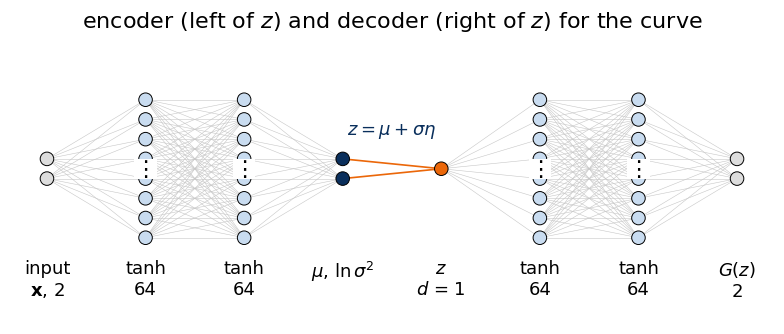

In [4]:
def draw_network(ax, layers, max_nodes=10, gap=1.6, node_gap=0.32, title=""):
    """
    Draw a dense network as columns of nodes joined by lines.

    ax        : matplotlib axes to draw on
    layers    : list of dicts, one per column, from input to output. Keys:
                  n         number of units in the column
                  label     text written under the column
                  color     face colour of the nodes
                  link      text written above the connection that leads into this column (optional)
                  pairwise  True: node k of this column is joined only to nodes k and k + n of the previous
                            column, as in z_k = mu_k + sigma_k * eta_k (optional)
    max_nodes : a column with more units is drawn with max_nodes nodes and a vertical ellipsis
    gap       : horizontal distance between neighbouring columns
    node_gap  : vertical distance between neighbouring nodes; column height therefore grows with width,
                so the narrowing to the latent layer and the widening back are visible
    title     : title of the drawing
    """
    prev_ys, x = None, 0.0
    for L in layers:
        shown = min(L["n"], max_nodes)
        span = node_gap * (shown - 1) / 2
        ys = np.linspace(span, -span, shown) if shown > 1 else np.array([0.0])
        if prev_ys is not None:
            if L.get("pairwise"):                                   # element-wise link of equation (9)
                for k, y1 in enumerate(ys):
                    for y0 in (prev_ys[k], prev_ys[k + len(ys)]):
                        ax.plot([x - gap, x], [y0, y1], color=orange, lw=1.2, zorder=1)
            else:                                                   # full connection of two dense layers
                for y0 in prev_ys:
                    for y1 in ys:
                        ax.plot([x - gap, x], [y0, y1], color="0.78", lw=0.4, zorder=1)
            if L.get("link"):
                ax.text(x - gap / 2, max(span, prev_ys.max()) + 0.3, L["link"], ha="center", va="bottom",
                        fontsize=13, color=navy)
        for y in ys:                                                # the nodes themselves
            ax.add_patch(Circle((x, y), 0.11, fc=L["color"], ec="k", lw=0.7, zorder=3))
        if L["n"] > max_nodes:                                      # a truncated column
            ax.text(x, 0, "⋮", ha="center", va="center", fontsize=16, bbox=dict(fc="white", ec="none", pad=0), zorder=4)
        ax.text(x, -node_gap * (max_nodes - 1) / 2 - 0.35, L["label"], ha="center", va="top", fontsize=13)
        prev_ys, x = ys, x + gap
    half = node_gap * (max_nodes - 1) / 2
    ax.set_xlim(-0.6, x - gap + 0.6); ax.set_ylim(-half - 1.4, half + 1.0)
    ax.set_aspect("equal"); ax.axis("off")
    if title: ax.set_title(title, pad=8)
    return ax

c_in, c_hid, c_ms, c_lat = "#DDDDDD", "#C9DCF0", navy, orange
curve_layers = [
    dict(n=2, label="input\n$\\mathbf{x}$, 2", color=c_in),
    dict(n=64, label="tanh\n64", color=c_hid),
    dict(n=64, label="tanh\n64", color=c_hid),
    dict(n=2, label="$\\mu$, $\\ln\\sigma^2$", color=c_ms),
    dict(n=1, label="$z$\n$d$ = 1", color=c_lat, link="$z=\\mu+\\sigma\\eta$", pairwise=True),
    dict(n=64, label="tanh\n64", color=c_hid),
    dict(n=64, label="tanh\n64", color=c_hid),
    dict(n=2, label="$G(z)$\n2", color=c_in),
]
fig, ax = plt.subplots(figsize=(10, 3.6))
draw_network(ax, curve_layers, max_nodes=8, title="encoder (left of $z$) and decoder (right of $z$) for the curve")
plt.tight_layout(); plt.show()

Layer table with output shapes and parameter counts (`torchinfo`) and computational graph (`torchview`) of the same network; the graph shows the encoder and decoder modules and the sampling step of equation (9) between them.

Layer (type:depth-idx)                   Output Shape              Param #
CurveVAE                                 [1, 2]                    --
├─Sequential: 1-1                        [1, 2]                    --
│    └─Linear: 2-1                       [1, 64]                   192
│    └─Tanh: 2-2                         [1, 64]                   --
│    └─Linear: 2-3                       [1, 64]                   4,160
│    └─Tanh: 2-4                         [1, 64]                   --
│    └─Linear: 2-5                       [1, 2]                    130
├─Sequential: 1-2                        [1, 2]                    --
│    └─Linear: 2-6                       [1, 64]                   128
│    └─Tanh: 2-7                         [1, 64]                   --
│    └─Linear: 2-8                       [1, 64]                   4,160
│    └─Tanh: 2-9                         [1, 64]                   --
│    └─Linear: 2-10                      [1, 2]                    130
Total

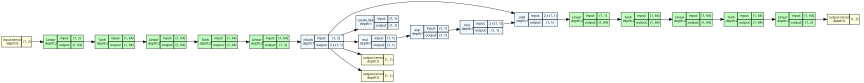

In [5]:
from torchinfo import summary
from torchview import draw_graph
print(summary(CurveVAE(1), input_size=(1, 2), col_names=("output_size", "num_params"), depth=2, verbose=0))
graph = draw_graph(CurveVAE(1), input_size=(1, 2), depth=2, graph_dir="LR", save_graph=False)
graph.visual_graph.render(f"{RES}/latent_curve_vae_torchview", format="png", cleanup=True)
graph.visual_graph

Training runs for 300 passes through the 4000 points with mini-batches of 128 and the Adam optimiser, with $\beta$ = 1, so that the loss is minus the ELBO of equation (11).

In [6]:
seed(1)
vae_c = CurveVAE(1)
t1 = time.time()
hist_c = train_vae(vae_c, Xc_t, lambda x, o: gauss_nll(x, o, s_noise), beta=1.0, epochs=300)
torch.save(vae_c.state_dict(), f"{RES}/latent_curve_vae.pt")
print(f"training time {time.time() - t1:.0f} s")
nums["curve_rec"], nums["curve_kl"] = float(hist_c[-1, 0]), float(hist_c[-1, 1])

epoch    0   reconstruction   127.861   KL   2.589


epoch   50   reconstruction    -2.413   KL   3.656


epoch  100   reconstruction    -2.831   KL   3.568


epoch  150   reconstruction    -3.046   KL   3.535


epoch  200   reconstruction    -2.994   KL   3.524


epoch  250   reconstruction    -3.069   KL   3.528


epoch  299   reconstruction    -3.005   KL   3.543
training time 55 s


### Latent line

After training, each data point has an encoder cloud on the latent line, with centre $\mu(\mathbf x)$ and width $\sigma(\mathbf x)$, and each latent value $z$ has a decoded point $G(z)$ in the plane. The centre plotted against the hidden $t$ shows which relabelling of $t$ the encoder has chosen; the decoder curve drawn over the data, with the latent values $-2,\dots,2$ marked, shows the map in the opposite direction.

Pearson correlation of mu with t  : +0.9811
Spearman (rank) correlation      : +0.9996
encoder width sigma: median 0.0276, range 0.0153 to 0.2651
range of mu over the data: -2.83 to 2.81; mean +0.014, std 1.062
x1 of the decoded point G(z) at z = -2, -1, 0, 1, 2: [-1.88 -1.3  -0.04  1.29  1.87]


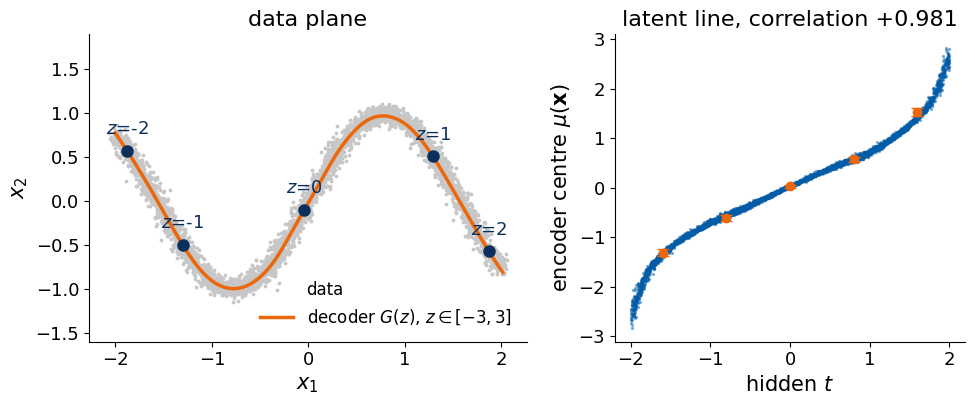

In [7]:
with torch.no_grad():
    mu_c, lv_c = vae_c.encode(Xc_t)
    mu_c, sd_c = mu_c[:, 0].numpy(), np.exp(0.5 * lv_c[:, 0].numpy())
    zline = torch.linspace(-3, 3, 601)[:, None]
    G_line = vae_c.dec(zline).numpy()
    G_ticks = vae_c.dec(torch.arange(-2, 3, dtype=torch.float32)[:, None]).numpy()
r_pearson = np.corrcoef(mu_c, t_c)[0, 1]
rank = lambda a: np.argsort(np.argsort(a))
r_spearman = np.corrcoef(rank(mu_c), rank(t_c))[0, 1]
sign_c = np.sign(r_pearson)                                       # the VAE may run along the curve either way
order = np.argsort(t_c)
monotone = np.mean(np.diff(sign_c * mu_c[order]) > -3 * np.median(sd_c))   # fraction of steps that do not go back
print(f"Pearson correlation of mu with t  : {r_pearson:+.4f}")
print(f"Spearman (rank) correlation      : {r_spearman:+.4f}")
print(f"encoder width sigma: median {np.median(sd_c):.4f}, range {sd_c.min():.4f} to {sd_c.max():.4f}")
print(f"range of mu over the data: {mu_c.min():.2f} to {mu_c.max():.2f}; mean {mu_c.mean():+.3f}, std {mu_c.std():.3f}")
print("x1 of the decoded point G(z) at z = -2, -1, 0, 1, 2:", np.round(G_ticks[:, 0], 2))
nums.update(curve_corr_pearson=float(r_pearson), curve_corr_spearman=float(r_spearman),
            curve_sigma_median=float(np.median(sd_c)), curve_mu_min=float(mu_c.min()), curve_mu_max=float(mu_c.max()))

fig, axs = plt.subplots(1, 2, figsize=(10, 4.3), gridspec_kw=dict(width_ratios=[1.25, 1]))
ax = axs[0]
ax.scatter(X_c[:, 0], X_c[:, 1], s=3, color="0.78", label="data")
ax.plot(G_line[:, 0], G_line[:, 1], color=orange, lw=2.5, label="decoder $G(z)$, $z\\in[-3,3]$")
for zt, g in zip(range(-2, 3), G_ticks):
    ax.plot(*g, "o", color=navy, ms=8, zorder=5)
    ax.annotate(f"$z$={zt}", g, xytext=(0, 12), textcoords="offset points", ha="center", fontsize=13, color=navy)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_title("data plane"); ax.set_ylim(-1.6, 1.9)
ax.legend(loc="lower right", frameon=False, fontsize=12); clean(ax)
ax = axs[1]
ax.scatter(t_c, mu_c, s=2, color=blue, alpha=0.4)
pick = [np.argmin(np.abs(t_c - v)) for v in (-1.6, -0.8, 0.0, 0.8, 1.6)]
for i in pick:
    ax.errorbar(t_c[i], mu_c[i], yerr=2 * sd_c[i], fmt="o", color=orange, ms=6, capsize=4, lw=2)
ax.set_xlabel("hidden $t$"); ax.set_ylabel("encoder centre $\\mu(\\mathbf{x})$")
ax.set_title(f"latent line, correlation {r_pearson:+.3f}")
clean(ax); plt.tight_layout()
plt.savefig(f"{OUT}/latent_curve.png", dpi=200, bbox_inches="tight"); plt.show()

The encoder has turned the hidden number into the latent coordinate: the rank (Spearman) correlation of $\mu$ with $t$ is 0.9996, so the order of the points along the curve is preserved almost without exception. The linear (Pearson) correlation, 0.981, is lower only because the relation is not a straight line: it is an S-shaped curve, flat in the middle and steep at both ends of the interval. The direction is arbitrary; another random initialisation could have produced the mirror image, $\mu$ decreasing with $t$, and the model would be equally good. The centres of the data run from −2.83 to 2.81, with mean 0.014 and standard deviation 1.062, close to the 0 and 1 of the prior. The clouds are narrow: the median width is 0.028 (from 0.015 to 0.27), so one data point fixes its latent value to a few hundredths; the ±2σ error bars of the five marked points hardly exceed the markers.

On the data plane the decoder curve runs through the middle of the band, and the latent ticks are not equally spaced along it. The decoded points of $z$ = −2, −1, 0, 1, 2 have horizontal coordinates −1.88, −1.30, −0.04, 1.29, 1.87: one unit of $z$ near the origin covers about 1.3 units of the curve's horizontal extent, the next unit only about 0.6. This unequal spacing is the stretching that decides where generated points fall.

The encoder clouds of all data points together form the aggregate posterior, the distribution of latent values that the data as a whole occupy,
$$q_\phi(z)=\frac1N\sum_{i=1}^{N}q_\phi(z\,|\,\mathbf x_i). \tag{12}$$
The KL term pulls every cloud towards the prior, and if the training has succeeded, the clouds tile the prior: their sum, equation (12), should look like $p(z)$, so that a latent value drawn from the prior falls where some data point has put its cloud. Five single clouds, scaled to be visible, and the sum over all 4000 points are compared with the prior.

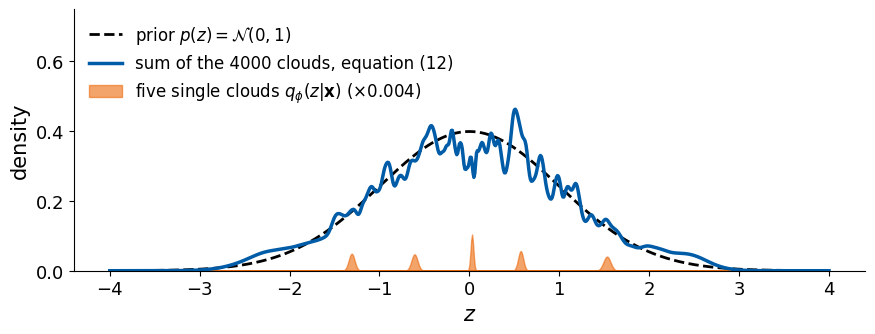

largest gap between the summed clouds and the prior: 0.131


In [8]:
zz = np.linspace(-4, 4, 801)
agg = np.mean(norm.pdf(zz[None, :], mu_c[:, None], sd_c[:, None]), 0)       # equation (12)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(zz, norm.pdf(zz), color="k", lw=2, ls="--", label="prior $p(z)=\\mathcal{N}(0,1)$")
ax.plot(zz, agg, color=blue, lw=2.5, label="sum of the 4000 clouds, equation (12)")
for i in pick:
    ax.fill_between(zz, 0, 0.004 * norm.pdf(zz, mu_c[i], sd_c[i]), color=orange, alpha=0.6)
ax.fill_between([], [], color=orange, alpha=0.6, label="five single clouds $q_\\phi(z|\\mathbf{x})$ (×0.004)")
ax.set_ylim(0, 0.75); ax.set_xlabel("$z$"); ax.set_ylabel("density"); ax.legend(frameon=False, loc="upper left", fontsize=12); clean(ax)
plt.tight_layout(); plt.show()
print(f"largest gap between the summed clouds and the prior: {np.max(np.abs(agg - norm.pdf(zz))):.3f}")

The sum of the clouds follows the prior with a largest deviation of 0.131 in density. Its wiggles come from the narrowness of the single clouds: 4000 bumps of width about 0.03 do not add up to a perfectly smooth curve, and with more data they would average out. No single cloud resembles the prior. The average KL divergence per point at the end of training is 3.54 nats, and by equation (8) almost all of it is $-\ln\sigma$, about 3.6 for $\sigma$ = 0.028: the price, in nats, of pinning the latent value of a point down to a width of 0.03 inside a prior of width 1. The prior is filled collectively, by the spread of the cloud centres; this is the property that makes sampling from the prior meaningful.

### Sampling the curve

To generate a new point, we draw a latent value from the prior and pass it through the decoder, equation (5): first the mean $G(z)$, then, if we want points with the same blur as the data, a Gaussian step of width $\sigma_x$ around it. Where along the curve the new points fall is decided by two things, the prior density $p(z)$ and how fast the decoder moves along the curve when $z$ changes. Let $T(z)$ be the horizontal coordinate of $G(z)$, which for this curve is the position $t$ along it. If $T$ is monotonic, a short latent interval $dz$ is mapped to a stretch of length $|dT/dz|\,dz$, and the probability $p(z)\,dz$ is spread over that stretch, so the generated points have the density
$$p(t)=\frac{p(z)}{\left|dT/dz\right|},\qquad z=T^{-1}(t). \tag{13}$$
A decoder that moves fast (large $|dT/dz|$) thins the points out; one that moves slowly piles them up. The data have the uniform density 1/4 on $[-2,2]$, and equation (13) gives it only if the decoder stretches the Gaussian exactly as the inverse of its cumulative distribution function $\Phi$ does,
$$T(z)=\pm\big(4\,\Phi(z)-2\big),\qquad \Phi(z)=\int_{-\infty}^{z}\mathcal N(z';0,1)\,dz' . \tag{14}$$
The sign depends on the direction in which the VAE runs along the curve. Near $z$ = 0, where the prior is dense, equation (14) moves fast; in the tails, where the prior is thin, it slows down and squeezes the last stretch of the curve into a long range of $z$.

fraction of generated points with x1 inside [-2, 2]: 0.992
largest deviation of the decoder T(z) from equation (14) on [-2.5, 2.5]: 0.120
std of the histogram of x1 over [-1.8, 1.8]: data 0.0137, generated 0.0301


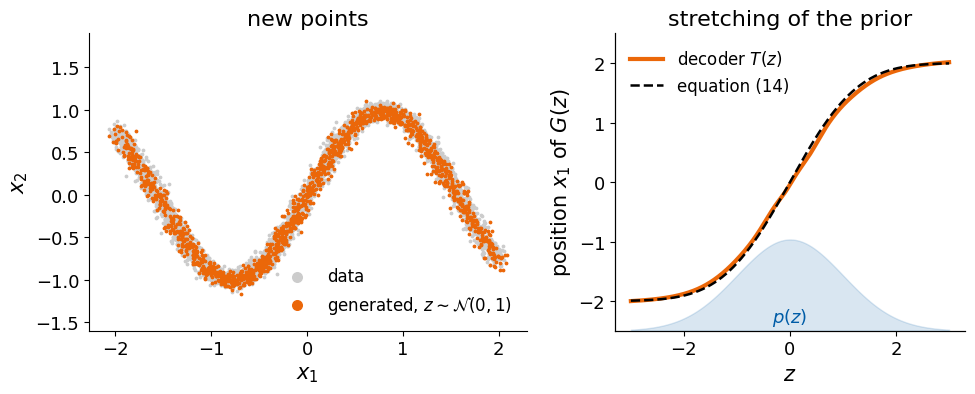

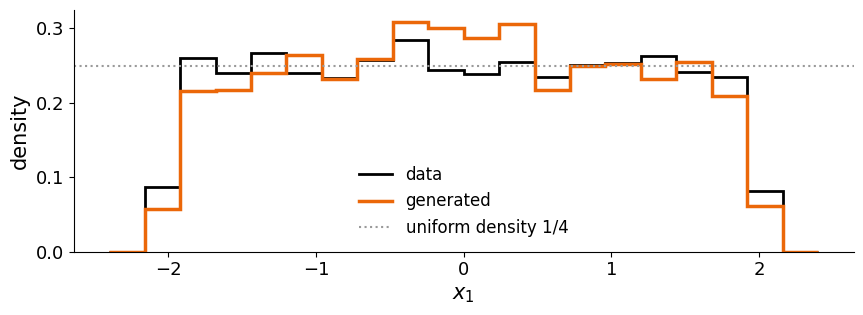

In [9]:
rng = seed(2)
n_gen = 4000
with torch.no_grad():
    z_gen = torch.randn(n_gen, 1)                                         # z ~ N(0, 1)
    G_gen = vae_c.dec(z_gen).numpy()                                      # mean of the decoder
x_gen = G_gen + s_noise * rng.standard_normal(G_gen.shape)                # plus the decoder noise, equation (5)
T_ideal = sign_c * (4 * norm.cdf(zline[:, 0].numpy()) - 2)                 # equation (14)
cover = np.mean((x_gen[:, 0] > -2) & (x_gen[:, 0] < 2))
hist_d, edges = np.histogram(X_c[:, 0], bins=20, range=(-2.4, 2.4), density=True)
hist_g, _ = np.histogram(x_gen[:, 0], bins=20, range=(-2.4, 2.4), density=True)
print(f"fraction of generated points with x1 inside [-2, 2]: {cover:.3f}")
print(f"largest deviation of the decoder T(z) from equation (14) on [-2.5, 2.5]: "
      f"{np.max(np.abs(G_line[100:501, 0] - T_ideal[100:501])):.3f}")
print(f"std of the histogram of x1 over [-1.8, 1.8]: data {hist_d[3:17].std():.4f}, generated {hist_g[3:17].std():.4f}")
nums["curve_gen_inside"] = float(cover)
nums["curve_T_dev"] = float(np.max(np.abs(G_line[100:501, 0] - T_ideal[100:501])))

fig, axs = plt.subplots(1, 2, figsize=(10, 4.2), gridspec_kw=dict(width_ratios=[1.25, 1]))
ax = axs[0]
ax.scatter(X_c[:, 0], X_c[:, 1], s=3, color="0.8", label="data")
ax.scatter(x_gen[:1500, 0], x_gen[:1500, 1], s=3, color=orange, label="generated, $z\\sim\\mathcal{N}(0,1)$")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_title("new points"); ax.set_ylim(-1.6, 1.9)
ax.legend(frameon=False, loc="lower right", fontsize=12, markerscale=4); clean(ax)
ax = axs[1]
ax.plot(zline[:, 0], G_line[:, 0], color=orange, lw=3, label="decoder $T(z)$")
ax.plot(zline[:, 0], T_ideal, color="k", ls="--", lw=1.8, label="equation (14)")
ax2 = ax.twinx()
ax2.fill_between(zline[:, 0], 0, norm.pdf(zline[:, 0]), color=blue, alpha=0.15)
ax2.set_ylim(0, 1.3); ax2.set_yticks([]); ax2.spines[["top", "right"]].set_visible(False)
ax.text(0, -2.35, "$p(z)$", color=blue, ha="center", fontsize=13)
ax.set_xlabel("$z$"); ax.set_ylabel("position $x_1$ of $G(z)$"); ax.set_title("stretching of the prior")
ax.set_ylim(-2.5, 2.5); ax.legend(frameon=False, loc="upper left", fontsize=12); clean(ax)
plt.tight_layout(); plt.savefig(f"{OUT}/latent_curve_sampling.png", dpi=200, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.stairs(hist_d, edges, color="k", lw=2, label="data")
ax.stairs(hist_g, edges, color=orange, lw=2.5, label="generated")
ax.axhline(0.25, color=grey, ls=":", label="uniform density 1/4")
ax.set_xlabel("$x_1$"); ax.set_ylabel("density"); ax.legend(frameon=False, fontsize=12, loc="lower center"); clean(ax)
plt.tight_layout(); plt.show()

Of the generated points, 99.2% have $x_1$ inside $[-2,2]$, and they cover the band with nearly uniform density. The decoder's $T(z)$ deviates from equation (14) by at most 0.12 on the interval $[-2.5,2.5]$ of $z$, so the decoder has found the inverse of the Gaussian cumulative distribution function by itself. Nothing in the loss mentions that $t$ is uniform. The transformation emerges because the KL term makes the latent values of the data distributed like the prior, and the decoder must then map that Gaussian back onto a uniformly filled curve. The consequence is visible in the tails: by equation (14) the last stretch of the curve, of length about 0.09 at each end (four times $\Phi(-2)$), receives all latent values beyond ±2, 2.3% of the prior on each side, so the decoder barely moves there.

The histogram of $x_1$ of the generated points is flat with a standard deviation of the bin heights (over the interior bins) of 0.030, against 0.014 for the data. With 4000 points and bins of width 0.24, the expected count per bin is 240 and the counting noise alone gives about 0.016; the remaining excess reflects small imperfections of the learnt stretching, mainly a surplus of about 20% of generated points in the middle of the curve, for $x_1$ between −0.5 and 0.5, where the decoder moves slightly too slowly.

### Weight of the KL term

The two terms of equation (10) pull in opposite directions. The reconstruction term wants each cloud narrow and the clouds of different points far apart, so that $z$ pins down $\mathbf x$; the KL term wants every cloud to be the prior itself. The same network trained with $\beta$ = 0.02 and $\beta$ = 20 shows the effect of each term on the latent line, the decoder curve and the generated points.

beta =  0.02: mu from  -3.99 to   4.04,  median sigma 0.0065,  corr(mu, t) +0.989
beta =     1: mu from  -2.83 to   2.81,  median sigma 0.0276,  corr(mu, t) +0.981
beta =    20: mu from  -2.20 to   2.19,  median sigma 0.1298,  corr(mu, t) +0.985


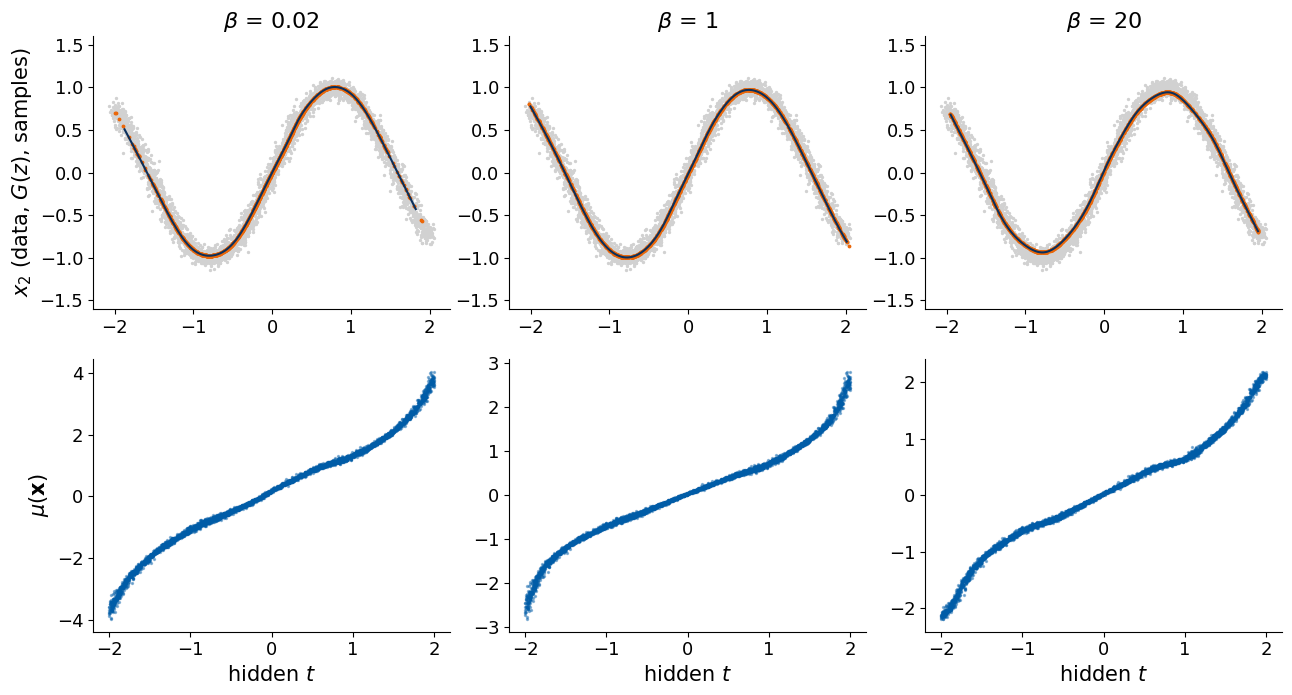

In [10]:
beta_runs = {}
for beta in (0.02, 20.0):
    seed(1)
    m = CurveVAE(1)
    train_vae(m, Xc_t, lambda x, o: gauss_nll(x, o, s_noise), beta=beta, epochs=300, report=0)
    torch.save(m.state_dict(), f"{RES}/latent_curve_vae_beta{beta:g}.pt")
    with torch.no_grad():
        mu, lv = m.encode(Xc_t)
        beta_runs[beta] = dict(mu=mu[:, 0].numpy(), sd=np.exp(0.5 * lv[:, 0].numpy()),
                               G=m.dec(zline).numpy(), gen=m.dec(torch.randn(1500, 1)).numpy())
beta_runs[1.0] = dict(mu=mu_c, sd=sd_c, G=G_line, gen=G_gen[:1500])
fig, axs = plt.subplots(2, 3, figsize=(13, 7.2))
for j, beta in enumerate((0.02, 1.0, 20.0)):
    r = beta_runs[beta]
    ax = axs[0, j]
    ax.scatter(X_c[:, 0], X_c[:, 1], s=2, color="0.82")
    ax.scatter(r["gen"][:, 0], r["gen"][:, 1], s=3, color=orange)
    ax.plot(r["G"][:, 0], r["G"][:, 1], color=navy, lw=1.5)
    ax.set_title(f"$\\beta$ = {beta:g}"); ax.set_ylim(-1.6, 1.6); clean(ax)
    ax = axs[1, j]
    ax.scatter(t_c, r["mu"], s=2, color=blue, alpha=0.4)
    ax.set_xlabel("hidden $t$"); clean(ax)
    print(f"beta = {beta:5g}: mu from {r['mu'].min():6.2f} to {r['mu'].max():6.2f},  median sigma {np.median(r['sd']):.4f},"
          f"  corr(mu, t) {np.corrcoef(r['mu'], t_c)[0, 1]:+.3f}")
    nums[f"curve_beta{beta:g}_sigma_median"] = float(np.median(r["sd"]))
    nums[f"curve_beta{beta:g}_mu_range"] = [float(r["mu"].min()), float(r["mu"].max())]
axs[0, 0].set_ylabel("$x_2$ (data, $G(z)$, samples)"); axs[1, 0].set_ylabel("$\\mu(\\mathbf{x})$")
plt.tight_layout(); plt.show()

With $\beta$ = 0.02 the KL term is almost switched off. The clouds shrink to a median width of 0.0065, four times narrower than with $\beta$ = 1, and the centres spread out to the range −3.99 to 4.04, beyond where the prior puts appreciable probability. The decoder curve for $z$ from −3 to 3 (dark line) then stops short of both ends of the data, and samples from the prior (orange) almost never reach the last part of the curve: the latent space is a good code but a poor generator, the autoencoder problem of the lecture returning.

With $\beta$ = 20 the KL term dominates. The clouds widen to a median of 0.13, the centres are squeezed to −2.20 to 2.19, and the decoder must produce one point for a whole cloud of latent values, that is, for a stretch of the curve. Its best answer is the average of that stretch, which lies on the inner side of every bend: the decoded curve cuts the corners of the sine and stops short of its ends. The correlation of $\mu$ with $t$ stays between 0.981 and 0.989 in all three runs; what $\beta$ changes is not the order of the latent values but how finely they resolve $t$ and how well they fill the prior.

## A bar at an angle

The second data set consists of 28×28 grey images of a white bar on a black background, the same size as the digits of the lecture. The bar has a fixed length $\ell$ = 16 pixels and width $w$ = 3 pixels and is drawn with anti-aliasing: a pixel at the edge of the bar takes an intermediate grey value instead of being either black or white, so that a small change of angle or position changes the image smoothly. Two hidden numbers are drawn for each image, the angle $\vartheta$ of the bar with the horizontal axis, uniform in $[0,\pi)$, and a horizontal shift $u$ of its centre, uniform in $[-6,6]$ pixels. An angle of $\pi$ gives the same picture as an angle of 0, so $\vartheta$ is a periodic cause with period $\pi$.

The image is computed pixel by pixel. For the pixel at position $(p_1,p_2)$, measured in pixels from the image centre (horizontal to the right, vertical upwards), the coordinates along the bar and across it are
$$a=(p_1-u)\cos\vartheta+p_2\sin\vartheta,\qquad b=-(p_1-u)\sin\vartheta+p_2\cos\vartheta, \tag{15}$$
and the grey value is the product of two ramps that are 1 inside the bar, 0 outside, and linear over one pixel at the edge,
$$x_{p}=\operatorname{clip}\!\big(\tfrac{\ell}{2}-|a|+\tfrac12\big)\cdot\operatorname{clip}\!\big(\tfrac{w}{2}-|b|+\tfrac12\big),\qquad \operatorname{clip}(v)=\min\big(1,\max(0,v)\big). \tag{16}$$
One sample is therefore a vector of 784 numbers in $[0,1]$, and its two causes $(\vartheta,u)$ are stored but never shown to the VAE. The data set has 20 000 images.

images: (20000, 784)  grey values from 0.0 to 1.0  mean 0.0612


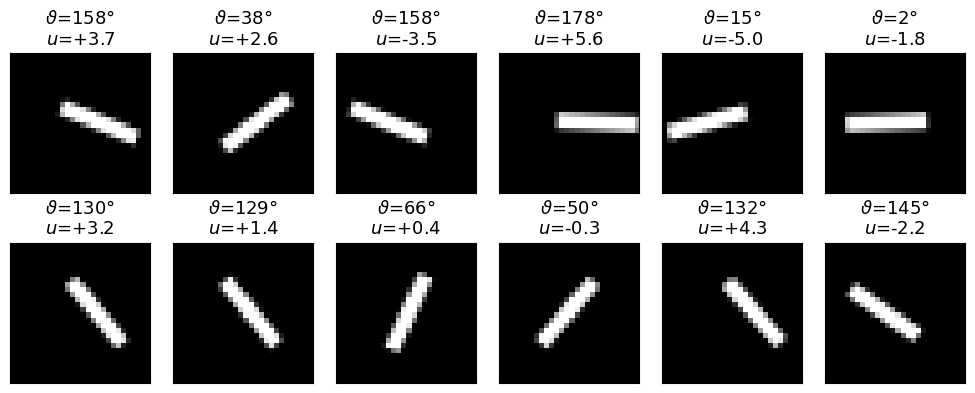

In [11]:
def render_bars(theta, u, length=16.0, width=3.0, n=28):
    """
    Render anti-aliased bars, equations (15) and (16).

    theta  : array of angles with the horizontal axis, in radians
    u      : array of horizontal shifts of the bar centre, in pixels (positive to the right)
    length : bar length in pixels (a number or an array with one value per image)
    width  : bar width in pixels
    n      : side of the square image in pixels
    returns an array of shape (len(theta), n, n) with grey values in [0, 1]
    """
    c = (n - 1) / 2
    rows, cols = np.mgrid[0:n, 0:n]
    p1 = cols[None] - c - np.asarray(u)[:, None, None]           # horizontal, relative to the bar centre
    p2 = -(rows[None] - c)                                        # vertical, upwards
    ct, st = np.cos(theta)[:, None, None], np.sin(theta)[:, None, None]
    a, b = p1 * ct + p2 * st, -p1 * st + p2 * ct                  # equation (15)
    length = np.asarray(length, dtype=float).reshape(-1, 1, 1) if np.ndim(length) else length
    ramp = lambda v: np.clip(v, 0, 1)
    return (ramp(length / 2 - np.abs(a) + 0.5) * ramp(width / 2 - np.abs(b) + 0.5)).astype(np.float32)   # equation (16)

rng = seed(3)
N_b = 20000
th_b = rng.uniform(0, np.pi, N_b)                                 # hidden angle
u_b = rng.uniform(-6, 6, N_b)                                     # hidden shift
X_b = render_bars(th_b, u_b).reshape(N_b, 784)
Xb_t = torch.tensor(X_b)
print("images:", X_b.shape, " grey values from", X_b.min(), "to", X_b.max(), " mean", round(float(X_b.mean()), 4))

idx = rng.choice(N_b, 12, replace=False)
fig, axs = plt.subplots(2, 6, figsize=(10, 4.2))
for ax, i in zip(axs.ravel(), idx):
    ax.imshow(X_b[i].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"$\\vartheta$={np.degrees(th_b[i]):.0f}°\n$u$={u_b[i]:+.1f}", fontsize=13)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig(f"{OUT}/latent_bar_examples.png", dpi=200, bbox_inches="tight"); plt.show()

Every image is a bar of the same size; only its orientation and its horizontal position change. The 784 grey values thus lie on a two-dimensional surface in $\mathbb R^{784}$, and because the angle is periodic, this surface is closed in one direction: following $\vartheta$ from 0 to $\pi$ at fixed $u$ returns to the starting image. The surface has the topology of a cylinder (a circle of angles times an interval of shifts).

The pixels are grey values between 0 and 1, so we use the Bernoulli decoder of the lecture. The decoder outputs, for each pixel $j$, a number $\hat x_j(\mathbf z)$ between 0 and 1, read as the probability that the pixel is white, and treats the pixels as independent given $\mathbf z$,
$$p_\theta(\mathbf x\,|\,\mathbf z)=\prod_{j=1}^{784}\hat x_j^{\,x_j}\,\big(1-\hat x_j\big)^{1-x_j}, \tag{17}$$
and the vector $\hat{\mathbf x}(\mathbf z)$ of these probabilities is the decoder mean $G(\mathbf z)$. Minus its logarithm is the binary cross-entropy (BCE),
$$-\log p_\theta(\mathbf x\,|\,\mathbf z)=-\sum_{j=1}^{784}\Big[x_j\log\hat x_j+(1-x_j)\log\big(1-\hat x_j\big)\Big]. \tag{18}$$
"Binary" refers to the two outcomes per pixel, white or black, and "cross-entropy" to the average surprise $-\log$ of the observed outcome under the predicted probabilities. Each pixel's term is small when the decoder gives a high probability to what the pixel actually is, and grows without bound for a confident wrong prediction. For grey values $x_j$ strictly between 0 and 1, equation (17) is no longer a normalised distribution, but equation (18) is still smallest when $\hat x_j$ equals $x_j$ and is the usual loss for such images. The encoder and decoder are dense networks with hidden layers of 256 and 128 units and the rectified linear unit (ReLU), which returns its input when it is positive and 0 otherwise, as activation; the decoder's last layer outputs logits, numbers that the sigmoid turns into the probabilities $\hat x_j$, and the latent space has $d$ = 2 coordinates, as many as there are hidden causes.

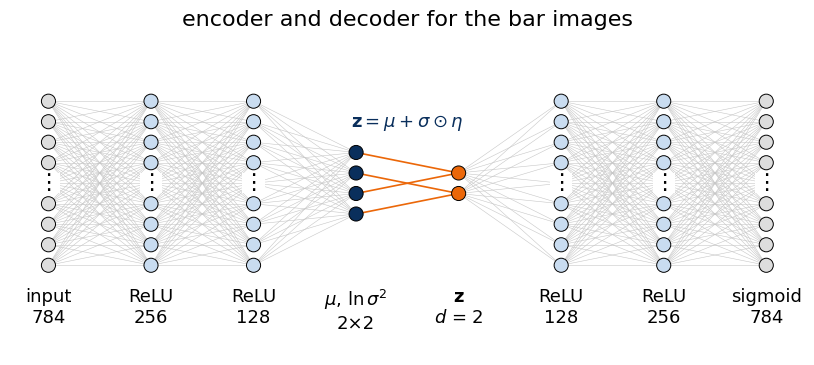

Layer (type:depth-idx)                   Output Shape              Param #
BarVAE                                   [1, 784]                  --
├─Sequential: 1-1                        [1, 4]                    --
│    └─Linear: 2-1                       [1, 256]                  200,960
│    └─ReLU: 2-2                         [1, 256]                  --
│    └─Linear: 2-3                       [1, 128]                  32,896
│    └─ReLU: 2-4                         [1, 128]                  --
│    └─Linear: 2-5                       [1, 4]                    516
├─Sequential: 1-2                        [1, 784]                  --
│    └─Linear: 2-6                       [1, 128]                  384
│    └─ReLU: 2-7                         [1, 128]                  --
│    └─Linear: 2-8                       [1, 256]                  33,024
│    └─ReLU: 2-9                         [1, 256]                  --
│    └─Linear: 2-10                      [1, 784]                  201

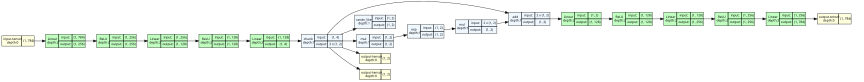

In [12]:
class BarVAE(nn.Module):
    """Dense VAE for 28 x 28 images: encoder 784 -> 256 -> 128 -> (mu, ln sigma^2), decoder d -> 128 -> 256 -> 784 logits."""
    def __init__(self, d=2):
        super().__init__()
        self.d = d
        self.enc = nn.Sequential(nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 2 * d))
        self.dec = nn.Sequential(nn.Linear(d, 128), nn.ReLU(), nn.Linear(128, 256), nn.ReLU(), nn.Linear(256, 784))
    def encode(self, x):
        mu, logvar = self.enc(x).chunk(2, dim=1)
        return mu, logvar
    def decode(self, z):
        return torch.sigmoid(self.dec(z))                          # decoder mean G(z), pixel probabilities
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)   # equation (9)
        return self.dec(z), mu, logvar                            # logits, for a numerically stable BCE

def bce_nll(x, logits):
    """Binary cross-entropy summed over the 784 pixels, equation (18), for every row."""
    return F.binary_cross_entropy_with_logits(logits, x, reduction="none").sum(1)

bar_layers = [
    dict(n=784, label="input\n784", color=c_in),
    dict(n=256, label="ReLU\n256", color=c_hid),
    dict(n=128, label="ReLU\n128", color=c_hid),
    dict(n=4, label="$\\mu$, $\\ln\\sigma^2$\n2×2", color=c_ms),
    dict(n=2, label="$\\mathbf{z}$\n$d$ = 2", color=c_lat, link="$\\mathbf{z}=\\mu+\\sigma\\odot\\eta$", pairwise=True),
    dict(n=128, label="ReLU\n128", color=c_hid),
    dict(n=256, label="ReLU\n256", color=c_hid),
    dict(n=784, label="sigmoid\n784", color=c_in),
]
fig, ax = plt.subplots(figsize=(10, 3.9))
draw_network(ax, bar_layers, max_nodes=9, title="encoder and decoder for the bar images")
plt.tight_layout(); plt.show()
print(summary(BarVAE(2), input_size=(1, 784), col_names=("output_size", "num_params"), depth=2, verbose=0))
graph = draw_graph(BarVAE(2), input_size=(1, 784), depth=2, graph_dir="LR", save_graph=False)
graph.visual_graph.render(f"{RES}/latent_bar_vae_torchview", format="png", cleanup=True)
graph.visual_graph

Training uses 40 passes through the 20 000 images with mini-batches of 128, Adam with learning rate $10^{-3}$, and $\beta$ = 1.

epoch    0   reconstruction   150.990   KL   0.854


epoch   10   reconstruction    30.187   KL   7.378


epoch   20   reconstruction    25.064   KL   7.311


epoch   30   reconstruction    23.651   KL   7.303


epoch   39   reconstruction    23.661   KL   7.273
training time 32 s
median encoder widths sigma_1, sigma_2: [0.025  0.0288]
mean absolute pixel error of the reconstruction from mu: 0.0067


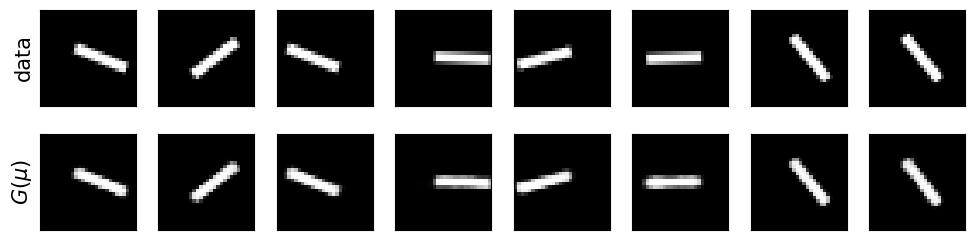

In [13]:
seed(4)
vae_b = BarVAE(2)
t1 = time.time()
hist_b = train_vae(vae_b, Xb_t, bce_nll, beta=1.0, epochs=40, lr=1e-3, report=10)
torch.save(vae_b.state_dict(), f"{RES}/latent_bar_vae.pt")
print(f"training time {time.time() - t1:.0f} s")
nums["bar_rec"], nums["bar_kl"] = float(hist_b[-1, 0]), float(hist_b[-1, 1])
with torch.no_grad():
    mu_b, lv_b = vae_b.encode(Xb_t)
    mu_b, sd_b = mu_b.numpy(), np.exp(0.5 * lv_b.numpy())
    rec_b = vae_b.decode(torch.tensor(mu_b)).numpy()
print("median encoder widths sigma_1, sigma_2:", np.round(np.median(sd_b, 0), 4))
print("mean absolute pixel error of the reconstruction from mu:", round(float(np.abs(rec_b - X_b).mean()), 4))
fig, axs = plt.subplots(2, 8, figsize=(10, 2.9))
for k, i in enumerate(idx[:8]):
    axs[0, k].imshow(X_b[i].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    axs[1, k].imshow(rec_b[i].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
for a in axs.ravel(): a.set_xticks([]); a.set_yticks([])
axs[0, 0].set_ylabel("data"); axs[1, 0].set_ylabel("$G(\\mu)$")
plt.tight_layout(); plt.show()

### Latent coordinates

Each image is a point $\boldsymbol\mu(\mathbf x)$ of the latent plane. The 20 000 points are coloured once by the hidden angle, with a cyclic colour map in which $\vartheta$ = 0 and $\vartheta$ = 180° have the same colour, and once by the hidden shift.

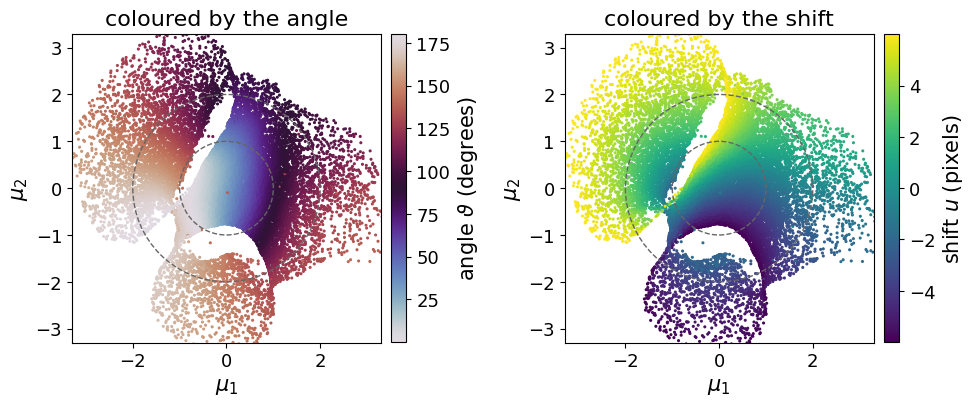

fraction of centres within radius 1 / 2 / 3: 0.366 / 0.789 / 0.973
N(0, I) would give                         : 0.393 / 0.865 / 0.989
|mean of exp(i(phi - 2 theta))| = 0.396,  |mean of exp(i(phi + 2 theta))| = 0.468  (1: polar angle follows the bar angle)
correlation of the radius with u: +0.239, with |u|: +0.360
correlation of mu_1 with u: -0.362, of mu_2 with u: +0.819


In [14]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, val, cmap, lab in [(axs[0], np.degrees(th_b), "twilight", "angle $\\vartheta$ (degrees)"),
                           (axs[1], u_b, "viridis", "shift $u$ (pixels)")]:
    sc = ax.scatter(mu_b[:, 0], mu_b[:, 1], c=val, cmap=cmap, s=1.5, rasterized=True)
    cb = plt.colorbar(sc, ax=ax, fraction=0.046, pad=0.03); cb.set_label(lab)
    for r in (1, 2): ax.add_patch(Circle((0, 0), r, fill=False, ls="--", color="0.4", lw=1))
    ax.set_xlabel("$\\mu_1$"); ax.set_ylabel("$\\mu_2$"); ax.set_aspect("equal")
    ax.set_xlim(-3.3, 3.3); ax.set_ylim(-3.3, 3.3)
axs[0].set_title("coloured by the angle"); axs[1].set_title("coloured by the shift")
plt.tight_layout(); plt.savefig(f"{OUT}/latent_bar_scatter.png", dpi=200, bbox_inches="tight"); plt.show()

# polar description of the latent cloud: radius and polar angle of mu
rad = np.hypot(mu_b[:, 0], mu_b[:, 1]); phi = np.arctan2(mu_b[:, 1], mu_b[:, 0])
# circular correlation of the latent polar angle with 2*theta (the bar angle doubled has period 2 pi)
c2 = np.abs(np.mean(np.exp(1j * (phi - 2 * th_b)))); c2m = np.abs(np.mean(np.exp(1j * (phi + 2 * th_b))))
print(f"fraction of centres within radius 1 / 2 / 3: {np.mean(rad < 1):.3f} / {np.mean(rad < 2):.3f} / {np.mean(rad < 3):.3f}")
print(f"N(0, I) would give                         : {1 - np.exp(-0.5):.3f} / {1 - np.exp(-2):.3f} / {1 - np.exp(-4.5):.3f}")
print(f"|mean of exp(i(phi - 2 theta))| = {c2:.3f},  |mean of exp(i(phi + 2 theta))| = {c2m:.3f}  (1: polar angle follows the bar angle)")
print(f"correlation of the radius with u: {np.corrcoef(rad, u_b)[0, 1]:+.3f}, with |u|: {np.corrcoef(rad, np.abs(u_b))[0, 1]:+.3f}")
print(f"correlation of mu_1 with u: {np.corrcoef(mu_b[:, 0], u_b)[0, 1]:+.3f}, of mu_2 with u: {np.corrcoef(mu_b[:, 1], u_b)[0, 1]:+.3f}")
nums.update(bar_frac_r1=float(np.mean(rad < 1)), bar_frac_r2=float(np.mean(rad < 2)),
            bar_circ_corr=float(max(c2, c2m)), bar_rad_u_corr=float(np.corrcoef(rad, u_b)[0, 1]),
            bar_sigma_median=[float(v) for v in np.median(sd_b, 0)])

After 40 passes the loss per image is 23.7 nats of reconstruction (the BCE of equation (18), which for grey pixels cannot reach zero) and 7.3 nats of KL divergence; the decoded centres $G(\boldsymbol\mu)$ differ from the images by 0.0067 per pixel on average, and the median encoder widths are 0.025 and 0.029.

The shift is the simpler of the two causes: it increases from the bottom to the top of the plane, and its correlation with $\mu_2$ is +0.82 (with $\mu_1$ −0.36). The angle is arranged around the plane, as the cyclic colours show, but not as a clean ring around the origin: the polar angle of $\boldsymbol\mu$ is only loosely tied to $2\vartheta$ (the modulus of the circular correlation is 0.47, where a perfect ring would give 1). There are narrow empty cracks where no training image lands, and the colours on the two sides of a crack belong to quite different angles. The centres fill the prior a little less tightly than $\mathcal N(0,I)$ itself: 36.6%, 78.9% and 97.3% of them lie within radius 1, 2 and 3, against 39.3%, 86.5% and 98.9% for the prior.

The scatter plot shows where the training images go; the decoder defines an angle at every latent point, including points between and beyond the training clouds. The orientation of a grey image can be read from its second moments. With $I_p$ the grey value of pixel $p$ at position $(p_1,p_2)$, $(c_1,c_2)$ the ink-weighted centre, and
$$m_{20}=\sum_p I_p\,(p_1-c_1)^2,\qquad m_{02}=\sum_p I_p\,(p_2-c_2)^2,\qquad m_{11}=\sum_p I_p\,(p_1-c_1)(p_2-c_2), \tag{19}$$
the long axis of the ink distribution makes the angle
$$\hat\vartheta=\tfrac12\operatorname{atan2}\big(2m_{11},\,m_{20}-m_{02}\big) \tag{20}$$
with the horizontal axis, where $\operatorname{atan2}(y,x)$ is the polar angle of the point $(x,y)$. Applied to the decoder mean $G(\mathbf z)$ on a fine latent grid, equation (20) gives an angle field $\hat\vartheta(\mathbf z)$ over the plane. Because the bar angle is periodic with period $\pi$, the natural variable is $2\hat\vartheta$, a direction in the plane, exactly like the spin direction of the XY model. Following $2\hat\vartheta$ around a small closed loop of four grid points and adding the four changes (each taken in $(-\pi,\pi]$) gives a multiple of $2\pi$; a nonzero multiple marks a point around which the decoded bar turns through a full half-turn, a vortex of the angle field. A continuous, one-to-one map of the cylinder of bars into the plane must wind around such a point, which the prior then fills with latent values that decode to no proper bar.

equation (20) on 2000 training images: median |error| 0.02 degrees


vortices of the decoded angle field with |z| < 2.5: 2
   at z = (+0.23, -1.02), charge -1
   at z = (-0.42, +0.93), charge +1
total ink of a clear bar 48.0; prior probability of latent points whose decoded image has less than 85% of it: 0.055


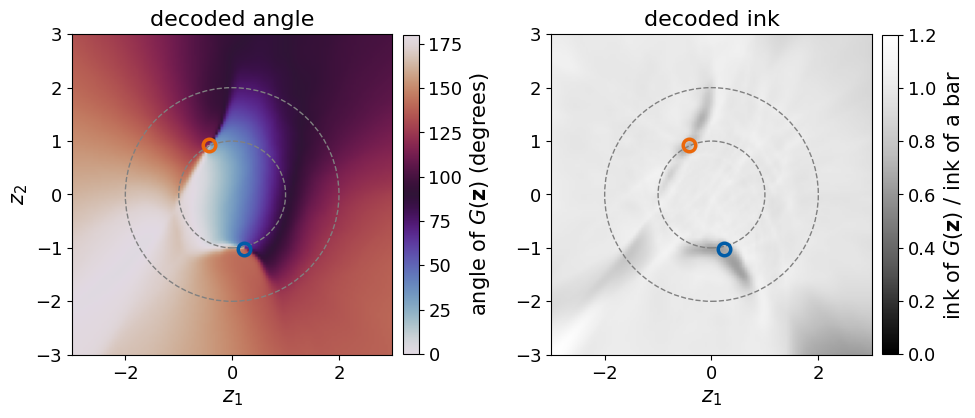

In [15]:
def bar_angle(imgs):
    """Orientation (radians, in [0, pi)) and total ink of 28 x 28 images from their second moments, equations (19)-(20)."""
    I = imgs.reshape(-1, 28, 28).astype(np.float64)
    rows, cols = np.mgrid[0:28, 0:28]; p1, p2 = cols - 13.5, -(rows - 13.5)
    m = I.sum((1, 2)) + 1e-9
    c1, c2 = (I * p1).sum((1, 2)) / m, (I * p2).sum((1, 2)) / m
    d1, d2 = p1[None] - c1[:, None, None], p2[None] - c2[:, None, None]
    m20, m02, m11 = (I * d1 ** 2).sum((1, 2)), (I * d2 ** 2).sum((1, 2)), (I * d1 * d2).sum((1, 2))
    return np.mod(0.5 * np.arctan2(2 * m11, m20 - m02), np.pi), m

th_hat, _ = bar_angle(X_b[:2000])
err = np.degrees(np.angle(np.exp(2j * (th_hat - th_b[:2000])))) / 2
print(f"equation (20) on 2000 training images: median |error| {np.median(np.abs(err)):.2f} degrees")

gf = np.linspace(-3, 3, 121)
Zf = torch.tensor([[a, b] for b in gf for a in gf], dtype=torch.float32)          # rows: z2 from -3 upwards
with torch.no_grad(): dec_f = vae_b.decode(Zf).numpy()
ang_f, ink_f = bar_angle(dec_f); ang_f, ink_f = ang_f.reshape(121, 121), ink_f.reshape(121, 121)
wrap = lambda v: np.angle(np.exp(1j * v))
A = 2 * ang_f
dx, dy = wrap(A[:, 1:] - A[:, :-1]), wrap(A[1:, :] - A[:-1, :])
circ = np.rint((dx[:-1, :] + dy[:, 1:] - dx[1:, :] - dy[:, :-1]) / (2 * np.pi)).astype(int)   # one value per plaquette
iy, ix = np.nonzero(circ)
vort = np.stack([(gf[ix] + gf[ix + 1]) / 2, (gf[iy] + gf[iy + 1]) / 2, circ[iy, ix]], 1)
inside = vort[np.hypot(vort[:, 0], vort[:, 1]) < 2.5]
print(f"vortices of the decoded angle field with |z| < 2.5: {len(inside)}")
for v in inside: print(f"   at z = ({v[0]:+.2f}, {v[1]:+.2f}), charge {int(v[2]):+d}")
ink_clear = render_bars(np.array([0.3]), np.array([0.0])).sum()
weak = ink_f < 0.85 * ink_clear
pz = norm.pdf(Zf.numpy()).prod(1).reshape(121, 121); pz /= pz.sum()
print(f"total ink of a clear bar {ink_clear:.1f}; prior probability of latent points whose decoded image has "
      f"less than 85% of it: {pz[weak].sum():.3f}")
nums.update(bar_angle_moment_err_deg=float(np.median(np.abs(err))), bar_n_vortices=int(len(inside)),
            bar_vortices=[[float(v[0]), float(v[1]), int(v[2])] for v in inside], bar_prior_weak_ink=float(pz[weak].sum()))

fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
im = axs[0].imshow(np.degrees(ang_f), origin="lower", extent=[-3, 3, -3, 3], cmap="twilight", vmin=0, vmax=180)
cb = plt.colorbar(im, ax=axs[0], fraction=0.046, pad=0.03); cb.set_label("angle of $G(\\mathbf{z})$ (degrees)")
im2 = axs[1].imshow(ink_f / ink_clear, origin="lower", extent=[-3, 3, -3, 3], cmap="Greys_r", vmin=0, vmax=1.2)
cb2 = plt.colorbar(im2, ax=axs[1], fraction=0.046, pad=0.03); cb2.set_label("ink of $G(\\mathbf{z})$ / ink of a bar")
for ax in axs:
    for v in inside:
        ax.plot(v[0], v[1], "o", ms=9, mfc="none", mec=orange if v[2] > 0 else blue, mew=2.5)
    for r in (1, 2): ax.add_patch(Circle((0, 0), r, fill=False, ls="--", color="0.5", lw=1))
    ax.set_xlabel("$z_1$"); ax.set_aspect("equal")
axs[0].set_ylabel("$z_2$"); axs[0].set_title("decoded angle"); axs[1].set_title("decoded ink")
plt.tight_layout(); plt.savefig(f"{OUT}/latent_bar_angle_field.png", dpi=200, bbox_inches="tight"); plt.show()

Equation (20) recovers the angle of the training bars to 0.02° (median error), so it reads the decoder output reliably. The decoded angle field has two vortices inside radius 2.5: one of charge +1 near the latent point (−0.42, 0.93) and one of charge −1 near (0.23, −1.02). Around a small loop enclosing the first, the decoded bar turns once through all angles; around the second it turns once in the opposite sense; around a large loop enclosing both, the two turns cancel. The ink panel shows what happens near the cores: along thin streaks starting at the vortices, the decoded image has less ink than a bar, because the decoder interpolates between bars of different orientation, and the average of two different bars is a faint cross or blob. The prior probability of latent points whose decoded image has less than 85% of the ink of a bar is 0.055: about one random latent point in eighteen falls on a seam.

This structure is forced by topology. If every decoded image were a bar with a well-defined angle, $2\hat\vartheta(\mathbf z)$ would be a continuous map from the plane to the circle, and such a map turns zero times around every closed loop. The bars of one shift, however, form a closed loop of images, $\vartheta$ from 0 to π, and the encoder maps them to a closed loop in the latent plane around which the decoded angle turns once. Inside that loop the decoder must therefore produce images without a well-defined angle: a vortex core. Topology fixes only the net charge enclosed by such a loop, +1; how the vortices are arranged is left to the training. A single vortex with the bars on a ring around it is one possibility, several vortices of opposite charge connected by seams is another. This model produced a vortex–antivortex pair, placed close to the origin where the prior is dense; a different random initialisation can give a different arrangement. The Gaussian prior has no hole, so in either case some prior probability lands on latent points that decode to no proper bar.

### Latent grid and latent path

The scatter plot says where the images go; the decoder says what each latent point means. A regular 13×13 grid of latent points, both coordinates $z_1$ and $z_2$ in $[-2.5,2.5]$, is decoded, and each image $G(\mathbf z)$ is placed in the cell at the same position: column = value of $z_1$, row = value of $z_2$ (bottom to top). The orange line is a straight path between the encoder centres of two training images, A and B, with ten equally spaced points decoded along it.

path from z_A = [-0.26 -0.48] (theta 20 deg, u -4.0) to z_B = [-0.84  1.86] (theta 111 deg, u +4.0)


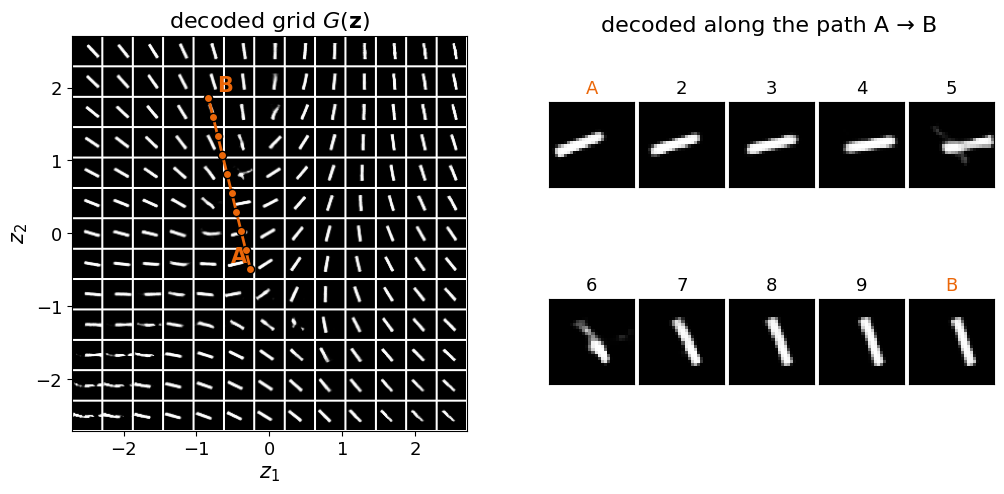

In [16]:
g = np.linspace(-2.5, 2.5, 13)
Zg = torch.tensor([[a, b] for b in g[::-1] for a in g], dtype=torch.float32)   # rows: z2 from top (2.5) to bottom (-2.5)
with torch.no_grad(): grid_img = vae_b.decode(Zg).numpy().reshape(13, 13, 28, 28)
sheet = np.ones((13 * 30, 13 * 30))
for r in range(13):
    for c in range(13): sheet[r * 30 + 1:r * 30 + 29, c * 30 + 1:c * 30 + 29] = grid_img[r, c]

# path between the encoder centres of two bars: a nearly horizontal bar at the left and a steep bar at the right
iA = np.argmin(np.abs(th_b - np.radians(20)) + np.abs(u_b + 4) / 10)
iB = np.argmin(np.abs(th_b - np.radians(110)) + np.abs(u_b - 4) / 10)
lam = np.linspace(0, 1, 10)[:, None]
Zp = (1 - lam) * mu_b[iA] + lam * mu_b[iB]
with torch.no_grad(): path_img = vae_b.decode(torch.tensor(Zp, dtype=torch.float32)).numpy().reshape(10, 28, 28)
print(f"path from z_A = {np.round(mu_b[iA], 2)} (theta {np.degrees(th_b[iA]):.0f} deg, u {u_b[iA]:+.1f})"
      f" to z_B = {np.round(mu_b[iB], 2)} (theta {np.degrees(th_b[iB]):.0f} deg, u {u_b[iB]:+.1f})")

fig = plt.figure(figsize=(10, 4.7))
ax = fig.add_axes([0.04, 0.1, 0.44, 0.84])
half = 2.5 + 5 / 12 / 2                                            # half a cell beyond the outermost grid point
ax.imshow(sheet, cmap="gray", vmin=0, vmax=1, extent=[-half, half, -half, half])
ax.plot(Zp[:, 0], Zp[:, 1], "-", color=orange, lw=2)
for k, (a, b) in enumerate(Zp):
    ax.plot(a, b, "o", color=orange, ms=6, mec="k")
ax.annotate("A", Zp[0], xytext=(-14, 4), textcoords="offset points", color=orange, fontsize=15, weight="bold")
ax.annotate("B", Zp[-1], xytext=(6, 4), textcoords="offset points", color=orange, fontsize=15, weight="bold")
ax.set_xlabel("$z_1$"); ax.set_ylabel("$z_2$"); ax.set_title("decoded grid $G(\\mathbf{z})$")
for k in range(10):
    axk = fig.add_axes([0.54 + 0.09 * (k % 5), 0.53 - 0.42 * (k // 5), 0.085, 0.36])
    axk.imshow(path_img[k], cmap="gray", vmin=0, vmax=1); axk.set_xticks([]); axk.set_yticks([])
    axk.set_title("A" if k == 0 else ("B" if k == 9 else f"{k + 1}"), fontsize=13, color=orange if k in (0, 9) else "k")
fig.text(0.76, 0.95, "decoded along the path A → B", ha="center", fontsize=16)
plt.savefig(f"{OUT}/latent_bar_path_grid.png", dpi=200, bbox_inches="tight"); plt.show()

Inside the square the grid is a map of bars. Both latent directions change both causes, and the clearest pattern is the rotation of the bars around the two vortex points of the angle field, near which the cells contain split or bent images; the shift, a few pixels within each small cell, is harder to see at this size. The path starts at the encoder centre of a bar with $\vartheta$ = 20° and $u$ = −4, the latent point (−0.26, −0.48), and ends at that of a bar with $\vartheta$ = 111° and $u$ = +4, the latent point (−0.84, 1.86). Images 1 to 4 rotate the bar slowly towards the horizontal, images 5 and 6 are crossings of two bars, and from image 7 on a steep bar moves to the right. The straight latent line passes close to the +1 vortex, where the decoded angle jumps; a path that goes around the vortex would turn the bar smoothly. A straight line in latent space is not, in general, the most natural route between two images.

### New bars

Generation uses only the decoder: draw $\mathbf z$ from the prior of equation (2) and show the decoder mean $G(\mathbf z)$. A numerical judgement of the new images comes from a dictionary of 36 000 noiseless bars rendered on a fine grid of angles and shifts: the dictionary bar closest to a generated image estimates the angle and shift that the image shows, and the root-mean-square pixel distance to it measures how bar-like the image is.

rms distance to the closest clean bar: generated median 0.0226, reconstructions median 0.0217
generated images with rms below the 95th percentile of the reconstructions: 0.823


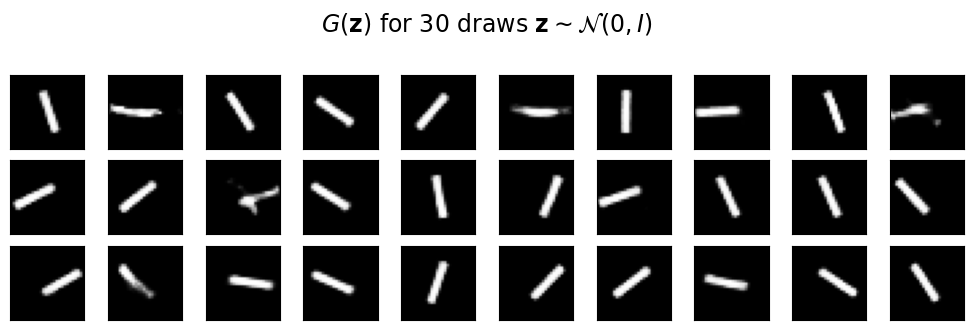

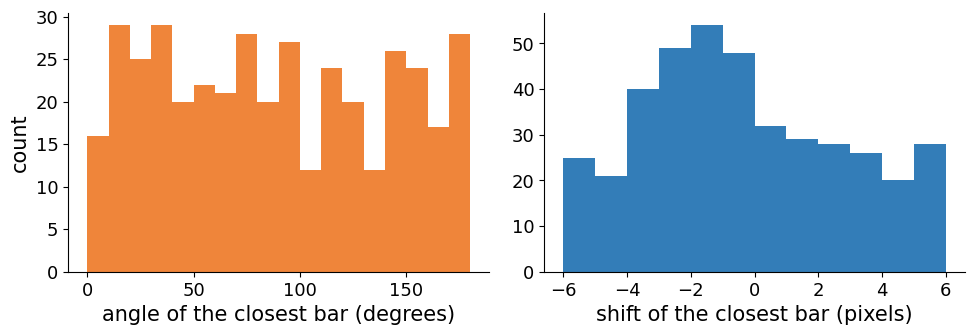

In [17]:
rng = seed(5)
n_s = 400
with torch.no_grad(): samp = vae_b.decode(torch.randn(n_s, 2)).numpy()
# dictionary of clean bars: 360 angles x 100 shifts
th_d, u_d = np.meshgrid(np.linspace(0, np.pi, 360, endpoint=False), np.linspace(-6, 6, 100))
dict_img = render_bars(th_d.ravel(), u_d.ravel()).reshape(-1, 784)
def nearest_bar(imgs):
    """Index of, and root-mean-square pixel distance to, the closest dictionary bar for every image."""
    d2 = (imgs ** 2).sum(1)[:, None] - 2 * imgs @ dict_img.T + (dict_img ** 2).sum(1)[None, :]
    j = np.argmin(d2, 1)
    return j, np.sqrt(np.maximum(d2[np.arange(len(imgs)), j], 0) / 784)
j_s, rms_s = nearest_bar(samp)
j_r, rms_r = nearest_bar(rec_b[:400])                           # reconstructions of training images, for reference
print(f"rms distance to the closest clean bar: generated median {np.median(rms_s):.4f}, "
      f"reconstructions median {np.median(rms_r):.4f}")
print(f"generated images with rms below the 95th percentile of the reconstructions: "
      f"{np.mean(rms_s < np.percentile(rms_r, 95)):.3f}")
nums.update(bar_gen_rms_median=float(np.median(rms_s)), bar_rec_rms_median=float(np.median(rms_r)),
            bar_gen_frac_barlike=float(np.mean(rms_s < np.percentile(rms_r, 95))))
fig, axs = plt.subplots(3, 10, figsize=(10, 3.4))
for k, ax in enumerate(axs.ravel()):
    ax.imshow(samp[k].reshape(28, 28), cmap="gray", vmin=0, vmax=1); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("$G(\\mathbf{z})$ for 30 draws $\\mathbf{z}\\sim\\mathcal{N}(0,I)$", y=0.98)
plt.tight_layout(); plt.show()
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
axs[0].hist(np.degrees(th_d.ravel()[j_s]), bins=18, range=(0, 180), color=orange, alpha=0.8)
axs[0].set_xlabel("angle of the closest bar (degrees)"); axs[0].set_ylabel("count")
axs[1].hist(u_d.ravel()[j_s], bins=12, range=(-6, 6), color=blue, alpha=0.8)
axs[1].set_xlabel("shift of the closest bar (pixels)")
for a in axs: clean(a)
plt.tight_layout(); plt.show()

Most draws give clean bars. The median distance of a generated image to the closest clean bar is 0.0226, close to the 0.0217 of the reconstructions of training images, and 82.3% of the generated images are as close to a clean bar as 95% of the reconstructions. The rest, about one in six, are the split, bent or faint images that come from latent points near the vortices and seams. The angles of the generated bars cover 0° to 180° without a preferred direction (between 12 and 29 per 10° bin, against 22 expected for a uniform angle). The shifts are not uniform: shifts between −3 and −1 pixels occur about 50 times per 1-pixel bin, against 33 expected, well beyond the counting noise of about 6. The decoder spends more of the prior on these bars than the data contain, a mismatch between the aggregate of the encoder clouds and the prior.

## Probability in the latent space

The prior $p(\mathbf z)$ of equation (2) is a statement about all images the model can produce before any image is observed: with the decoder fixed, drawing $\mathbf z$ from the prior is drawing a bar, and the prior density is spread over the whole family of bars. Observing one image narrows this down. By Bayes' rule, the latent values that could have produced the image $\mathbf x$ have the posterior density
$$p_\theta(\mathbf z\,|\,\mathbf x)=\frac{p_\theta(\mathbf x\,|\,\mathbf z)\,p(\mathbf z)}{p_\theta(\mathbf x)}, \tag{21}$$
the prior reweighted by how well each $\mathbf z$ explains the image, divided by the normalisation $p_\theta(\mathbf x)$ of equation (1). The encoder cloud $q_\phi(\mathbf z\,|\,\mathbf x)$ is a Gaussian approximation to this posterior, learnt so that one network evaluation gives it for any image. Its width is the model's uncertainty about the causes: an image that fixes the angle and the shift sharply should have a small cloud, an image that leaves them open a wide one.

Images that carry less information than the training bars test this. A short bar (length 6 instead of 16 pixels) leaves its angle less certain; a faint bar (grey values multiplied by 0.3) has a weaker signal in every pixel; a bar buried in strong pixel noise (Gaussian, standard deviation 0.5, clipped to $[0,1]$) is partly hidden. None of these images was seen in training, so the encoder must extrapolate. With $d$ = 2 the posterior of equation (21) can also be evaluated directly on a fine grid of latent points, without the encoder, by computing the decoder likelihood of the image at every grid point; this gives the reference against which the encoder cloud is judged.

In [18]:
rng = seed(6)
n_t = 300
th_t, u_t = rng.uniform(0, np.pi, n_t), rng.uniform(-6, 6, n_t)
variants = {
    "clear":  render_bars(th_t, u_t),
    "short":  render_bars(th_t, u_t, length=6.0),
    "faint":  0.3 * render_bars(th_t, u_t),
    "noisy":  np.clip(render_bars(th_t, u_t) + 0.5 * rng.standard_normal((n_t, 28, 28)), 0, 1).astype(np.float32),
}
# exact posterior, equation (21): a coarse grid over the whole latent plane finds the region of high posterior,
# a fine grid around it resolves the shape (the posterior of a clear bar is narrower than the coarse spacing)
log_prior2 = lambda Z: norm.logpdf(Z).sum(1)
def log_post(img, Z, logits=None):
    """Unnormalised log posterior, log p(x|z) + log p(z), at the latent points Z (array of shape (n, 2));
    `logits` are the decoder outputs at Z if already computed."""
    x = torch.tensor(img.reshape(1, 784)).expand(len(Z), 784)
    with torch.no_grad():
        if logits is None: logits = vae_b.dec(torch.tensor(Z, dtype=torch.float32))
        ll = -F.binary_cross_entropy_with_logits(logits, x, reduction="none").sum(1)
    return ll.numpy() + log_prior2(Z)
def square_grid(centre, half, n):
    """Axis values and the n x n points of a square grid of half-width `half` around `centre`."""
    a1, a2 = np.linspace(centre[0] - half, centre[0] + half, n), np.linspace(centre[1] - half, centre[1] + half, n)
    A, B = np.meshgrid(a1, a2)
    return a1, a2, np.stack([A.ravel(), B.ravel()], 1)
_, _, Zc = square_grid((0, 0), 3.5, 141)                             # coarse grid: spacing 0.05
with torch.no_grad(): logits_c = vae_b.dec(torch.tensor(Zc, dtype=torch.float32))
def grid_posterior(img):
    """Posterior density of equation (21) on a fine 121 x 121 grid (spacing 0.0067) around its maximum.
    Returns (axis 1 values, axis 2 values, density array with rows along axis 2)."""
    lp = log_post(img, Zc, logits_c); centre = Zc[np.argmax(lp)]
    a1, a2, Zf = square_grid(centre, 0.4, 121)                       # fine grid
    lp = log_post(img, Zf); w = np.exp(lp - lp.max())
    h = a1[1] - a1[0]; w /= w.sum() * h * h
    return a1, a2, w.reshape(121, 121)
def post_moments(a1, a2, P):
    """Mean and widths of a posterior on a grid; the widths are the square roots of the eigenvalues of its covariance."""
    A, B = np.meshgrid(a1, a2); w = P / P.sum()
    m1, m2 = (w * A).sum(), (w * B).sum()
    C = np.array([[(w * (A - m1) ** 2).sum(), (w * (A - m1) * (B - m2)).sum()],
                  [(w * (A - m1) * (B - m2)).sum(), (w * (B - m2) ** 2).sum()]])
    return np.array([m1, m2]), np.sqrt(np.linalg.eigvalsh(C))[::-1]

cloud = {}
print("                 encoder: geometric mean of sigma_1, sigma_2       exact posterior (40 images): geometric mean of its two widths")
for name, imgs in variants.items():
    with torch.no_grad(): m, lv = vae_b.encode(torch.tensor(imgs.reshape(n_t, 784)))
    sd = np.exp(0.5 * lv.numpy())
    gm = np.sqrt(sd[:, 0] * sd[:, 1])
    widths = np.array([post_moments(*grid_posterior(imgs[i]))[1] for i in range(40)])   # (larger, smaller) width
    post_w = np.sqrt(widths[:, 0] * widths[:, 1])
    cloud[name] = dict(mu=m.numpy(), sd=sd, gm=gm, post=post_w)
    print(f"  {name:6s}         median {np.median(gm):.4f}  (10-90%: {np.percentile(gm, 10):.4f}-{np.percentile(gm, 90):.4f})"
          f"            median {np.median(post_w):.4f}  (larger width: median {np.median(widths[:, 0]):.4f})")
    nums[f"bar_post_width_large_{name}"] = float(np.median(widths[:, 0]))
    nums[f"bar_sigma_{name}"] = float(np.median(gm)); nums[f"bar_post_width_{name}"] = float(np.median(post_w))

                 encoder: geometric mean of sigma_1, sigma_2       exact posterior (40 images): geometric mean of its two widths


  clear          median 0.0270  (10-90%: 0.0192-0.0591)            median 0.0260  (larger width: median 0.0340)


  short          median 0.1829  (10-90%: 0.1519-0.2270)            median 0.0265  (larger width: median 0.0490)


  faint          median 0.2567  (10-90%: 0.2275-0.3355)            median 0.0320  (larger width: median 0.0452)


  noisy          median 0.0052  (10-90%: 0.0031-0.0096)            median 0.0160  (larger width: median 0.0179)


For clear bars the encoder and the exact posterior agree: the geometric mean of the two encoder widths is 0.027 (median), that of the exact posterior 0.026. Here the amortised approximation works, because these are the images it was trained on. For short and faint bars the encoder widens its clouds by factors of 7 and 10, to 0.183 and 0.257, the direction one expects for images that carry less information. The decoder's own posterior widens much less: its geometric-mean width grows only to 0.027 and 0.032, its larger width from 0.034 to 0.049 and 0.045. Under the model of equation (17) a short or faint bar still fixes its latent point well, because every one of the 784 pixels counts as independent evidence, and the posterior becomes elongated in one direction rather than wide. The noisy bars show the opposite failure: the encoder shrinks its clouds to 0.0052, five times narrower than the exact posterior (0.016), which is itself narrower than for a clear bar. The independent-pixel model takes every noisy pixel as reliable evidence and is overconfident; the encoder, extrapolating outside its training data, is more overconfident still. The width of an encoder cloud is the model's uncertainty only for inputs like those it was trained on and only to the extent that the decoder's noise model describes the data.

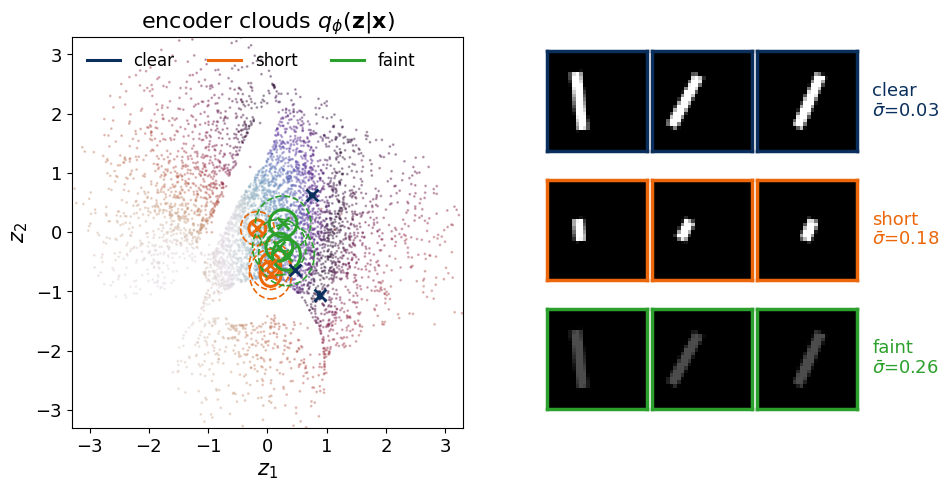

In [19]:
show = [0, 1, 2]                                                    # three test images
fig = plt.figure(figsize=(10, 4.6))
axL = fig.add_axes([0.05, 0.1, 0.46, 0.85])
axL.scatter(mu_b[::4, 0], mu_b[::4, 1], c=np.degrees(th_b[::4]), cmap="twilight", s=1, alpha=0.35, rasterized=True)
cols = {"clear": navy, "short": orange, "faint": "#2CA02C", "noisy": "#B22222"}
for name in ["clear", "short", "faint"]:
    c = cloud[name]
    for i in show:
        for k in (1, 2):                                           # ellipses at 1 and 2 sigma
            axL.add_patch(Ellipse(c["mu"][i], 2 * k * c["sd"][i, 0], 2 * k * c["sd"][i, 1], fill=False,
                                  ec=cols[name], lw=2.2 if k == 1 else 1.2, ls="-" if k == 1 else "--"))
        axL.plot(*c["mu"][i], "x", color=cols[name], ms=8, mew=2)
    axL.plot([], [], color=cols[name], lw=2.2, label=name)
axL.set_xlim(-3.3, 3.3); axL.set_ylim(-3.3, 3.3); axL.set_aspect("equal")
axL.set_xlabel("$z_1$"); axL.set_ylabel("$z_2$"); axL.legend(frameon=False, fontsize=12, loc="upper left", ncol=3)
axL.set_title("encoder clouds $q_\\phi(\\mathbf{z}|\\mathbf{x})$")
for r, name in enumerate(["clear", "short", "faint"]):
    for cidx, i in enumerate(show):
        a = fig.add_axes([0.56 + 0.105 * cidx, 0.68 - 0.28 * r, 0.1, 0.26])
        a.imshow(variants[name][i], cmap="gray", vmin=0, vmax=1); a.set_xticks([]); a.set_yticks([])
        for s in a.spines.values(): s.set_color(cols[name]); s.set_linewidth(2.5)
    fig.text(0.885, 0.81 - 0.28 * r, f"{name}\n$\\bar\\sigma$={np.median(cloud[name]['gm']):.2f}",
             fontsize=13, color=cols[name], va="center")
plt.savefig(f"{OUT}/latent_bar_clouds.png", dpi=200, bbox_inches="tight"); plt.show()

On the latent scatter (colours: the angle, as before) the clouds of the three clear bars are so small that only their centres are visible. The short and faint versions of the same bars have clouds several times wider, and their centres move towards the middle of the plane. When an image says little, the encoder falls back on the prior: a centre near 0 and a width closer to 1 cost the least KL divergence.

Exact posterior of equation (21) for the first test image of each kind (blue, evaluated on a grid of spacing 0.0067 around its maximum), with the encoder centre (cross) and its 1σ and 2σ ellipses in orange.

clear : posterior mean [ 0.883 -1.029], widths [0.029  0.0174];  encoder mu [ 0.888 -1.066], sigma [0.0203 0.0296]


short : posterior mean [ 0.574 -1.411], widths [0.1097 0.0191];  encoder mu [ 0.055 -0.705], sigma [0.1784 0.2102]


faint : posterior mean [ 0.59  -1.372], widths [0.0523 0.0178];  encoder mu [ 0.321 -0.382], sigma [0.2353 0.2601]


noisy : posterior mean [ 0.175 -1.165], widths [0.0183 0.0145];  encoder mu [ 1.695 -0.467], sigma [0.0048 0.0061]


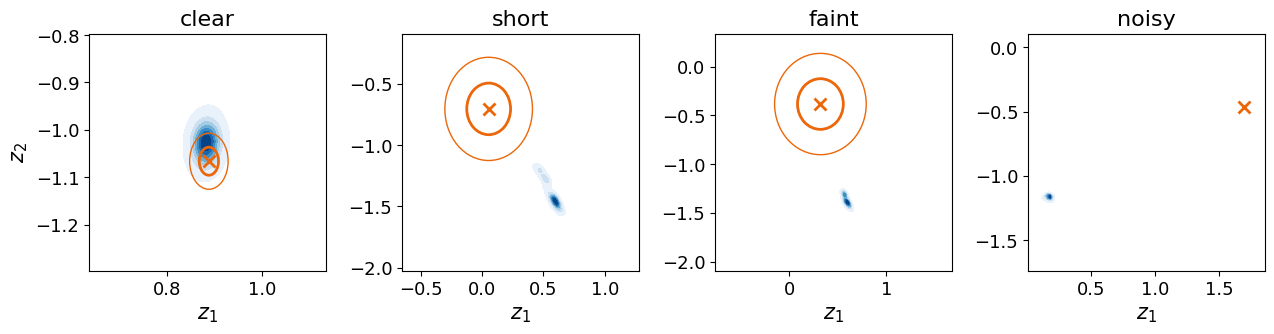

In [20]:
fig, axs = plt.subplots(1, 4, figsize=(13, 3.8))
for k, name in enumerate(["clear", "short", "faint", "noisy"]):
    i = show[0]
    a1, a2, P = grid_posterior(variants[name][i])
    m_p, w_p = post_moments(a1, a2, P)
    ax = axs[k]; c = cloud[name]
    ax.contourf(a1, a2, P, levels=np.linspace(0.02, 1, 8) * P.max(), cmap="Blues")
    for kk in (1, 2):
        ax.add_patch(Ellipse(c["mu"][i], 2 * kk * c["sd"][i, 0], 2 * kk * c["sd"][i, 1], fill=False, ec=orange, lw=2 if kk == 1 else 1))
    ax.plot(*c["mu"][i], "x", color=orange, ms=8, mew=2)
    centre = (m_p + c["mu"][i]) / 2
    half = max(0.25, 0.5 * np.abs(m_p - c["mu"][i]).max() + 0.15 + 2.2 * c["sd"][i].max())
    ax.set_xlim(centre[0] - half, centre[0] + half); ax.set_ylim(centre[1] - half, centre[1] + half); ax.set_aspect("equal")
    ax.set_title(name); ax.set_xlabel("$z_1$")
    print(f"{name:6s}: posterior mean {np.round(m_p, 3)}, widths {np.round(w_p, 4)};  encoder mu {np.round(c['mu'][i], 3)}, sigma {np.round(c['sd'][i], 4)}")
axs[0].set_ylabel("$z_2$")
plt.tight_layout(); plt.show()

For the clear bar the exact posterior, centred at (0.883, −1.029) with widths 0.029 and 0.017, and the encoder cloud, centred at (0.888, −1.066) with widths 0.020 and 0.030, nearly coincide. For the short bar the posterior is a thin streak, 0.110 long and 0.019 wide, at (0.574, −1.411): one combination of the latent coordinates is fixed sharply and the other is left open, the ambiguity that the short bar was designed to create. The encoder places its cloud elsewhere, at (0.055, −0.705), with widths 0.18 and 0.21. The faint bar behaves in the same way with a less elongated posterior (0.052 by 0.018), and for the noisy bar the encoder cloud (widths about 0.005) lies at (1.695, −0.467), far from the posterior at (0.175, −1.165): confident and wrong.

### Continuous mixture

Equation (1) has a concrete meaning that is easiest to see with the curve. Replace the integral over $z$ by a sum over a fine grid of latent values $z_m$ with spacing $\Delta z$:
$$p_\theta(\mathbf x)\approx\sum_{m}\underbrace{p(z_m)\,\Delta z}_{\text{weight } w_m}\ \mathcal N\big(\mathbf x;\,G(z_m),\,\sigma_x^2 I\big). \tag{22}$$
This is a Gaussian mixture: every latent grid point contributes one small Gaussian bump of width $\sigma_x$ centred on the curve point $G(z_m)$, with the prior probability of its latent interval as weight. The three-component Gaussian mixture of the lecture,
$$p(\mathbf x)=\sum_{k=1}^{3}\pi_k\,\mathcal N\big(\mathbf x;\,\mathbf m_k,\Sigma_k\big), \tag{23}$$
is the same construction with a discrete latent variable $z$ taking the values 1, 2 and 3, prior probabilities $\pi_k$, and a free mean $\mathbf m_k$ and covariance $\Sigma_k$ for each component. The VAE takes the limit of infinitely many components, but ties their means together on a smooth curve $G(z)$ and lets all of them share one small width. Equation (23) with three components is fitted to the curve data with scikit-learn, by the expectation-maximisation algorithm, which alternates between assigning each point to the components in proportion to their densities at the point and refitting every component to its weighted points. Equation (22) is evaluated for the trained VAE on a grid of 4001 latent values in $[-6,6]$. Both are compared on 2000 fresh points of equation (4) through the mean log-likelihood per point, together with a 30-component mixture and with the true process of equation (4), which is itself a continuous mixture over $t$ with the exact curve and noise. The ELBO of equation (11) is computed for the same points, with the average over each encoder cloud evaluated by Gauss–Hermite quadrature (a weighted sum over 80 fixed points of the Gaussian, accurate to many digits for smooth integrands); it must lie below the VAE log-likelihood for every point.

mean log-likelihood per fresh point:  GMM K=3 -0.850   GMM K=30 -0.388   VAE -0.401   true process -0.360
mean ELBO of the VAE: -0.552   (gap log p - ELBO: 0.151, fraction of points with ELBO <= log p: 1.000)


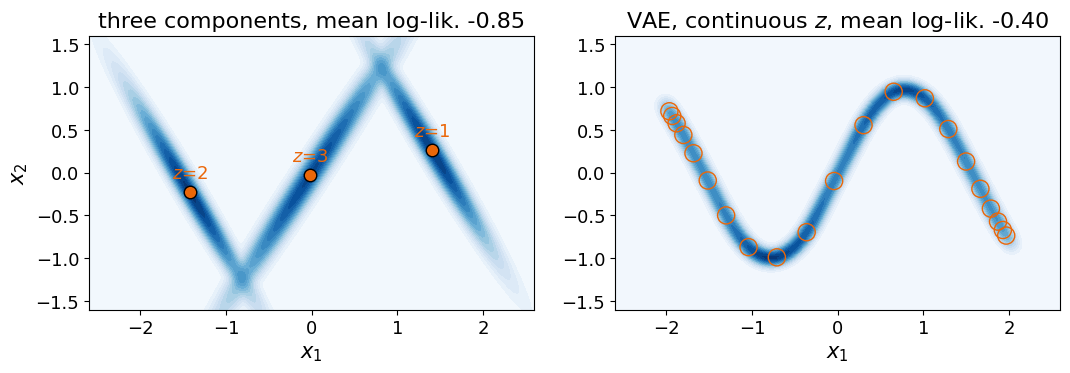

In [21]:
from sklearn.mixture import GaussianMixture
rng = seed(7)
t_new = rng.uniform(-2, 2, 2000)
X_new = np.stack([t_new, np.sin(2 * t_new)], 1) + s_noise * rng.standard_normal((2000, 2))   # fresh points, equation (4)

zq = np.linspace(-6, 6, 4001); dzq = zq[1] - zq[0]
with torch.no_grad(): Gq = vae_c.dec(torch.tensor(zq, dtype=torch.float32)[:, None]).numpy()
log_w = norm.logpdf(zq) + np.log(dzq)                               # weights of equation (22)
def mixture_logp(X, centres, log_w, chunk=1000):
    """log of sum_m w_m N(x; centre_m, s^2 I) for every row of X, equation (22), in chunks of rows to save memory."""
    out = []
    for i in range(0, len(X), chunk):
        d2 = ((X[i:i + chunk, None, :] - centres[None, :, :]) ** 2).sum(-1)
        lc = log_w[None, :] - d2 / (2 * s_noise ** 2) - np.log(2 * np.pi * s_noise ** 2)
        mx = lc.max(1, keepdims=True)
        out.append((mx + np.log(np.exp(lc - mx).sum(1, keepdims=True)))[:, 0])
    return np.concatenate(out)
vae_logp = lambda X: mixture_logp(X, Gq, log_w)
# the true process of equation (4) is the same kind of mixture, over t uniform on [-2, 2] with the true curve
tq = np.linspace(-2, 2, 4001)
true_logp = lambda X: mixture_logp(X, np.stack([tq, np.sin(2 * tq)], 1), np.full(len(tq), np.log(4 / 4000 / 4)))
def elbo(X, n_nodes=80):
    """ELBO of equation (11) for every row of X; the average over the encoder cloud is computed with
    Gauss-Hermite quadrature on n_nodes points, so the result has no sampling noise."""
    nodes, weights = np.polynomial.hermite_e.hermegauss(n_nodes)      # integrates f(e) exp(-e^2/2) de
    weights = weights / np.sqrt(2 * np.pi)                            # now: average of f(e) over e ~ N(0, 1)
    with torch.no_grad():
        xt = torch.tensor(X, dtype=torch.float32)
        mu, lv = vae_c.encode(xt)
        z = mu[None] + torch.exp(0.5 * lv)[None] * torch.tensor(nodes, dtype=torch.float32)[:, None, None]
        ll = -gauss_nll(xt[None].expand(n_nodes, -1, -1).reshape(-1, 2), vae_c.dec(z.reshape(-1, 1)), s_noise).reshape(n_nodes, -1)
        return (torch.tensor(weights, dtype=torch.float32) @ ll - kl_gauss(mu, lv)).numpy()

lp_vae, el_vae, lp_true = vae_logp(X_new), elbo(X_new), true_logp(X_new)
gmms = {K: GaussianMixture(K, covariance_type="full", random_state=0).fit(X_c) for K in (3, 30)}
lp_gmm = {K: gmms[K].score_samples(X_new) for K in gmms}
print(f"mean log-likelihood per fresh point:  GMM K=3 {lp_gmm[3].mean():.3f}   GMM K=30 {lp_gmm[30].mean():.3f}   "
      f"VAE {lp_vae.mean():.3f}   true process {lp_true.mean():.3f}")
print(f"mean ELBO of the VAE: {el_vae.mean():.3f}   (gap log p - ELBO: {np.mean(lp_vae - el_vae):.3f}, "
      f"fraction of points with ELBO <= log p: {np.mean(el_vae <= lp_vae + 1e-6):.3f})")
nums.update(curve_ll_gmm3=float(lp_gmm[3].mean()), curve_ll_gmm30=float(lp_gmm[30].mean()),
            curve_ll_vae=float(lp_vae.mean()), curve_elbo=float(el_vae.mean()), curve_ll_true=float(lp_true.mean()))

g1, g2 = np.meshgrid(np.linspace(-2.6, 2.6, 260), np.linspace(-1.6, 1.6, 160))
P = np.stack([g1.ravel(), g2.ravel()], 1)
dens = {"gmm": np.exp(gmms[3].score_samples(P)).reshape(g1.shape), "vae": np.exp(vae_logp(P)).reshape(g1.shape)}
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axs[0]
ax.contourf(g1, g2, np.sqrt(dens["gmm"]), levels=20, cmap="Blues")
for k in range(3):
    ax.plot(*gmms[3].means_[k], "o", color=orange, ms=9, mec="k")
    ax.annotate(f"$z$={k + 1}", gmms[3].means_[k], xytext=(0, 10), textcoords="offset points", ha="center", color=orange, fontsize=13)
ax.set_title(f"three components, mean log-lik. {lp_gmm[3].mean():.2f}"); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax = axs[1]
ax.contourf(g1, g2, np.sqrt(dens["vae"]), levels=20, cmap="Blues")
for zt in np.linspace(-2.5, 2.5, 21):
    gp = vae_c.dec(torch.tensor([[zt]], dtype=torch.float32)).detach().numpy()[0]
    ax.add_patch(Circle(gp, 2 * s_noise, fill=False, ec=orange, lw=1))
ax.set_title(f"VAE, continuous $z$, mean log-lik. {lp_vae.mean():.2f}"); ax.set_xlabel("$x_1$")
for a in axs: a.set_aspect("equal")
plt.tight_layout(); plt.show()

The colour shows the square root of the density, which makes the thin band of the VAE visible. Three Gaussians cannot follow the curve: each covers a stretch of it with an elongated ellipse, and the mean log-likelihood of fresh points is −0.850. The VAE, a mixture with one continuous latent number, reaches −0.401, within 0.041 of the true process (−0.360), which is the best value any model can reach on average. A mixture of 30 Gaussians reaches a similar −0.388. The difference lies in the latent variable: the 30 component labels are an unordered list, while the VAE's $z$ is a coordinate along the curve, ordered like the hidden $t$, defined between the training points, and distributed like a known prior.

The ELBO of the fresh points is −0.552 on average, below the log-likelihood for every point, as equation (11) requires. The average gap of 0.151 nats is the KL divergence between the encoder clouds and the exact posteriors: the part of the likelihood that training by the ELBO gives up because the encoder is only a Gaussian approximation.

## Handwritten digits

On MNIST, the data set of handwritten digits used throughout the lecture, nobody knows the hidden causes. A digit is fixed by the identity of the character, the pen trajectory, the slant, the stroke width, the size, and much more, and none of these numbers is recorded. The VAE with $d$ = 2 of the lecture is therefore forced to squeeze many causes into two latent coordinates, and the latent plane, shown on the slide "The Latent Space of a VAE" (figure from the conditional-generation notebook of this lecture), can be judged only indirectly, through the labels: digits of one class gather in one region, although the labels were never used in training.

The toy data show what such a map is. Each region of the plane is a set of latent values that the decoder turns into similar images; the coordinates are smooth functions of the hidden causes, chosen by the VAE so that the clouds of all images together fill the Gaussian prior; the decoder stretches that Gaussian onto the data, which decides how often each kind of image is generated; and the width of a cloud reports how well an image fixes its own causes. What is lost on MNIST is only the ability to name the coordinates.

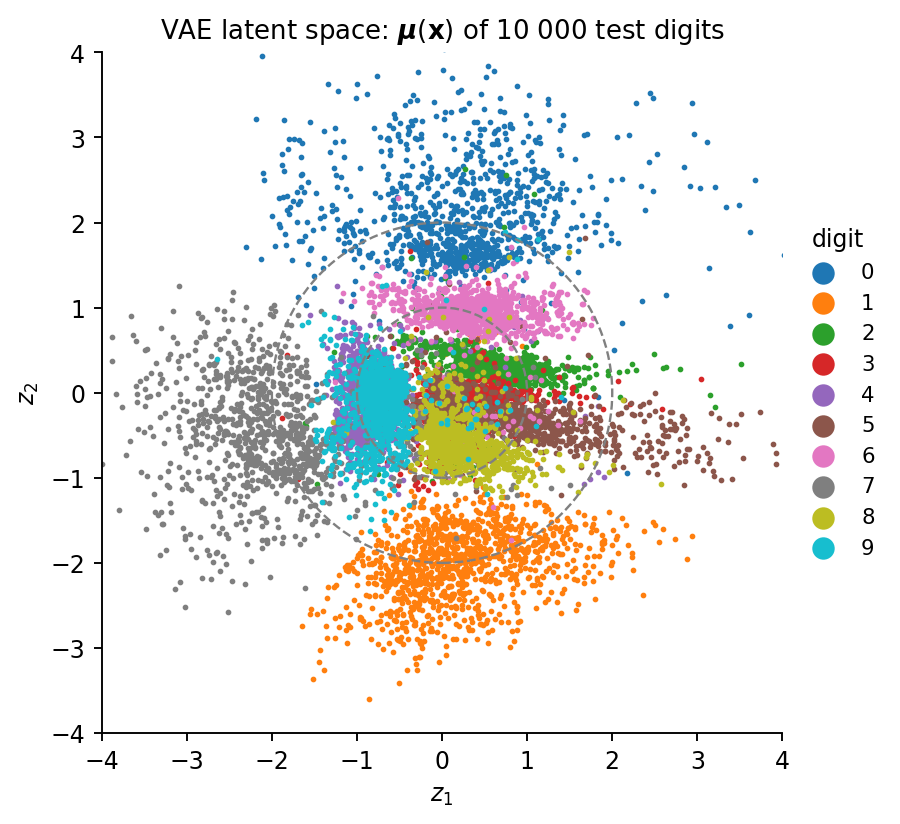

In [22]:
from IPython.display import Image, display
p = f"{OUT}/cond_vae_latent.png"
if os.path.exists(p): display(Image(p, width=480))

In [23]:
with open(f"{RES}/numbers_latent_space.json", "w") as f: json.dump(nums, f, indent=1)
print(json.dumps(nums, indent=1))
print(f"total run time {time.time() - T0:.0f} s")

{
 "curve_rec": -3.0047247505187986,
 "curve_kl": 3.5426286296844482,
 "curve_corr_pearson": 0.9810632222127983,
 "curve_corr_spearman": 0.9995931853495739,
 "curve_sigma_median": 0.02760663628578186,
 "curve_mu_min": -2.8253350257873535,
 "curve_mu_max": 2.8109254837036133,
 "curve_gen_inside": 0.99225,
 "curve_T_dev": 0.11985850781301677,
 "curve_beta0.02_sigma_median": 0.006483657285571098,
 "curve_beta0.02_mu_range": [
  -3.9867494106292725,
  4.044968605041504
 ],
 "curve_beta1_sigma_median": 0.02760663628578186,
 "curve_beta1_mu_range": [
  -2.8253350257873535,
  2.8109254837036133
 ],
 "curve_beta20_sigma_median": 0.12976740300655365,
 "curve_beta20_mu_range": [
  -2.1974000930786133,
  2.190171957015991
 ],
 "bar_rec": 23.661104693603516,
 "bar_kl": 7.272932639312744,
 "bar_frac_r1": 0.36635,
 "bar_frac_r2": 0.78885,
 "bar_circ_corr": 0.46816204071207823,
 "bar_rad_u_corr": 0.23866196369180206,
 "bar_sigma_median": [
  0.025013171136379242,
  0.028759490698575974
 ],
 "bar_angl